# **Project Name**    -  Yes Bank Monthly Closing Price Prediction (Regression)


##### **Project Type** - Regression
##### **Contribution** - Individual
##### **Student** - Rahul Sharma
##### **Programme** - B.Tech Information Technology (Hons.)
##### **Institution** - Panipat Institute of Engineering and Technology (PIET), Samalkha
##### **GitHub profile** - https://github.com/Mr-rxa

# **Project Summary -**

This project predicts the monthly closing price of Yes Bank stock from its monthly Open, High and Low prices, using 185 months of data from July 2005 to November 2020. Yes Bank has been in the news since 2018 because of the governance and fraud case around its co-founder Rana Kapoor, and its share price fell about 96% from the July 2018 peak (monthly close 367.90) to 14.67 in November 2020. Any model therefore has to work across a very wide range of price levels and through a crash.

The data were clean (no missing values, no duplicates, every month present, consistent High and Low), so preparation focused on the modelling set-up rather than on cleaning. Fifteen charts and three hypothesis tests established the facts that shaped the models. First, Open, High, Low and Close are almost perfectly correlated (0.978 to 0.995), but the predictors are severely multicollinear (VIF 35 to 82). Second, the spread of errors grows with the price level, and the risk regime changed after the peak: the median monthly range doubled from 17.5% to 35.2% of the opening price (Mann-Whitney p < 0.001) and the mean monthly log return fell from +2.1% to -11.7% (Welch p = 0.021). Third, monthly returns show no significant autocorrelation (lag-1 rho = 0.13, p = 0.07), a warning that forecasting next month's price from price history will be hard.

Feature engineering replaced raw prices by scale-free relative features: log(High/Open) and log(Low/Open) as inputs and log(Close/Open) as the target, converted back to rupees as Open times exp(prediction). This reduced the variance inflation factors from 35-82 to 1.0, and in time-series cross-validation on the training months it lowered the MAPE from 5.45% (raw prices) to 4.69%. The data were split chronologically: 148 months (Jul-05 to Oct-17) for training and 37 months (Nov-17 to Nov-20) for testing, so the test set contains the peak and the crash. A random split would leak the future into the past and was not used.

Three model families were built: Linear Regression (with a tuned Ridge variant), Random Forest and Gradient Boosting, each tuned by grid search over expanding-window cross-validation folds. A benchmark that simply predicts Close = Open scored R-squared 0.9085, RMSE 38.76 and MAPE 22.1%. Linear Regression was the best model with R-squared 0.9867, RMSE 14.79 INR, MAE 9.43 INR and MAPE 8.35%, cutting the benchmark error by about 62%. Tuned Gradient Boosting reached R-squared 0.9823 and Random Forest 0.9803 (0.9750 after tuning). Tuning helped Gradient Boosting slightly, did nothing for Ridge and hurt the Random Forest on the test months. Error analysis shows that the model is accurate in calm months (MAPE 2.5% before September 2018) but much less accurate during the crash (10.5%), and permutation importance shows that the month's low matters more than its high. The model was saved with joblib and reloaded successfully for a sanity check on unseen months.

A final check separates estimation from forecasting. The model uses the month's own High and Low, which are known only at month end, so it estimates the close instead of forecasting it. When the same approach was applied to genuine next-month forecasting from lagged information, no model beat the 'next close equals last close' benchmark (MAPE 22.5% for the benchmark against 23.6% for Ridge and 26.5% for Random Forest). The practical recommendation is to use the model for in-month estimation, reporting and scenario analysis, not as a trading signal, and to complement it with monitoring of range, volatility and drawdown.

# **GitHub Link -**

GitHub profile: https://github.com/Mr-rxa/Yes_Bank_Project2

# **Problem Statement**


**Yes Bank is a well-known Indian bank that has been in the news since 2018 because of the fraud case involving its co-founder Rana Kapoor. Given the monthly Open, High, Low and Close prices since its listing (Jul-2005 to Nov-2020), build and evaluate regression models that predict the closing price of the month, explain how well they work (especially around the 2018-2020 crash), and state honestly what the models can and cannot be used for.**

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [2]:
# Import Libraries
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                                   # reproducible results
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13})

ModuleNotFoundError: No module named 'joblib'

### Dataset Loading

In [ ]:
# Load Dataset
def load_data(filename="data_YesBank_StockPrices.csv"):
    """Read the CSV (same folder, /content for Colab, or ./data) and parse the 'Mon-YY' dates."""
    candidates = [Path(filename), Path("/content") / filename, Path("data") / filename,
                  Path("/content/drive/MyDrive") / filename]
    for path in candidates:
        if path.exists():
            frame = pd.read_csv(path)
            frame["Date"] = pd.to_datetime(frame["Date"], format="%b-%y")   # e.g. 'Jul-05' -> 2005-07-01
            return frame
    raise FileNotFoundError(f"{filename} not found. Keep it next to this notebook or upload it in Colab.")

raw = load_data()

### Dataset First View

In [ ]:
# Dataset First Look
display(raw.head())
display(raw.tail())

,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


,Date,Open,High,Low,Close
180,2020-07-01,25.60,28.30,11.10,11.95
181,2020-08-01,12.00,17.16,11.85,14.37
182,2020-09-01,14.30,15.34,12.75,13.15
183,2020-10-01,13.30,14.01,12.11,12.42
184,2020-11-01,12.41,14.90,12.21,14.67


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print(f"Rows: {raw.shape[0]}  |  Columns: {raw.shape[1]}")

Rows: 185  |  Columns: 5


### Dataset Information

In [ ]:
# Dataset Info
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    185 non-null    datetime64[us]
 1   Open    185 non-null    float64       
 2   High    185 non-null    float64       
 3   Low     185 non-null    float64       
 4   Close   185 non-null    float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 7.4 KB


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
print("Duplicate rows :", raw.duplicated().sum())
print("Duplicate dates:", raw["Date"].duplicated().sum())

Duplicate rows : 0
Duplicate dates: 0


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
print(raw.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


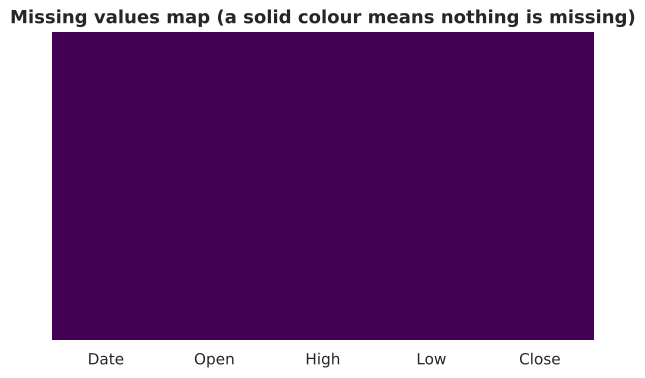

Largest gap between records (days): 31 -> every month is present
Rows where High < max(Open, Close): 0
Rows where Low  > min(Open, Close): 0
Rows where Open outside [Low, High]: 0


In [ ]:
# Visualizing the missing values
plt.figure(figsize=(7, 4))
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values map (a solid colour means nothing is missing)")
plt.show()

# Extra integrity checks: continuous monthly calendar and basic price logic
month_gaps = raw["Date"].sort_values().diff().dt.days.dropna()
print("Largest gap between records (days):", int(month_gaps.max()), "-> every month is present")
print("Rows where High < max(Open, Close):", int((raw["High"] < raw[["Open", "Close"]].max(axis=1)).sum()))
print("Rows where Low  > min(Open, Close):", int((raw["Low"] > raw[["Open", "Close"]].min(axis=1)).sum()))
print("Rows where Open outside [Low, High]:", int(((raw["Open"] > raw["High"]) | (raw["Open"] < raw["Low"])).sum()))

### What did you know about your dataset?

* The dataset has **185 rows and 5 columns**: a text date (`Mon-YY`) and four numeric price columns (Open, High, Low, Close). It covers **every month from Jul-2005 to Nov-2020** with no gaps, so it is a regular monthly time series.
* There are **no missing values and no duplicate rows**, and the price logic holds in every row (High is never below Open/Close, Low is never above them, Open lies inside the [Low, High] range).
* Prices range from about 10 to 404 INR, a 40-fold change, and the series has a structural break: it rose until Aug-2018 and then lost about 96% of its value.
* The target is **Close**. Open is known at the start of the month, but High and Low are only known at the end of the month. This matters for how the model can be used and is tested explicitly at the end of the modelling section.
* Because this is a time series, the split between training and test data must be chronological.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print(list(raw.columns))

['Date', 'Open', 'High', 'Low', 'Close']


In [ ]:
# Dataset Describe
display(raw.describe().round(2))

,Date,Open,High,Low,Close
count,185,185.00,185.00,185.00,185.00
mean,2013-03-01 19:04:12.972973,105.54,116.10,94.95,105.20
min,2005-07-01 00:00:00,10.00,11.24,5.55,9.98
25%,2009-05-01 00:00:00,33.80,36.14,28.51,33.45
50%,2013-03-01 00:00:00,62.98,72.55,58.00,62.54
75%,2017-01-01 00:00:00,153.00,169.19,138.35,153.30
max,2020-11-01 00:00:00,369.95,404.00,345.50,367.90
std,NaN,98.88,106.33,91.22,98.58


### Variables Description

| Variable | Type | Meaning |
|---|---|---|
| **Date** | datetime (month) | The month of the record, stored as text like `Jul-05` in the file |
| **Open** | float | Price at the start of the month (INR) |
| **High** | float | Highest price reached during the month (INR) |
| **Low** | float | Lowest price reached during the month (INR) |
| **Close** | float | Price at the end of the month (INR) – the **target variable** to predict |

*Note on the project brief:* the data-description table in the brief says "highest/lowest price in the day" and describes Close as "Occupations of the speaker". The second one is clearly a copy-paste error from another project, and because the file has one row per month, High and Low are the **monthly** extremes and Close is the **monthly closing price**.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for col in raw.columns:
    print(f"{col:<6} -> {raw[col].nunique():>3} unique values")

Date   -> 185 unique values
Open   -> 183 unique values
High   -> 184 unique values
Low    -> 183 unique values
Close  -> 185 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.
PEAK_DATE = pd.Timestamp("2018-08-01")      # month of the all-time monthly high (404.0)

def prepare_data(frame):
    """Return a chronologically sorted copy of the data with all analysis features added."""
    d = frame.copy().sort_values("Date").reset_index(drop=True)

    # --- calendar features
    d["Year"] = d["Date"].dt.year
    d["Month"] = d["Date"].dt.month
    d["Month_Name"] = d["Date"].dt.strftime("%b")

    # --- return and transformation features
    d["Return"] = d["Close"].pct_change() * 100                   # month-on-month % change of Close
    d["Log_Return"] = np.log(d["Close"]).diff()                   # month-on-month log return
    d["Log_Close"] = np.log(d["Close"])                           # removes the right skew of price

    # --- candle features
    d["Range_Pct"] = (d["High"] - d["Low"]) / d["Open"] * 100     # intra-month range as % of open
    d["Direction"] = np.where(d["Close"] >= d["Open"], "Up", "Down")

    # --- trend and risk features
    for window in (3, 6, 12):
        d[f"MA{window}"] = d["Close"].rolling(window).mean()      # moving averages
    d["Gap_vs_MA6"] = (d["Close"] / d["MA6"] - 1) * 100
    d["Drawdown"] = (d["Close"] / d["Close"].cummax() - 1) * 100  # % below the running peak
    d["Vol12"] = d["Return"].rolling(12).std()                    # 12-month rolling volatility
    d["Era"] = np.where(d["Date"] <= PEAK_DATE, "Rise (Jul-05 to Aug-18)", "Decline (Sep-18 to Nov-20)")
    return d

df = prepare_data(raw)

# Chronological train/test boundary (used by the charts and by the models later)
TRAIN_FRAC = 0.80
split_idx = int(len(df) * TRAIN_FRAC)
print(f"Train: {df['Date'].iloc[0]:%b-%Y} to {df['Date'].iloc[split_idx - 1]:%b-%Y} ({split_idx} months)")
print(f"Test : {df['Date'].iloc[split_idx]:%b-%Y} to {df['Date'].iloc[-1]:%b-%Y} ({len(df) - split_idx} months)")
display(df.head(3))

Train: Jul-2005 to Oct-2017 (148 months)
Test : Nov-2017 to Nov-2020 (37 months)


,Date,Open,High,Low,Close,Year,Month,Month_Name,Return,Log_Return,Log_Close,Range_Pct,Direction,MA3,MA6,MA12,Gap_vs_MA6,Drawdown,Vol12,Era
0,2005-07-01,13.00,14.00,11.25,12.46,2005,7,Jul,NaN,NaN,2.522524,21.153846,Down,NaN,NaN,NaN,NaN,0.000000,NaN,Rise (Jul-05 to Aug-18)
1,2005-08-01,12.58,14.88,12.55,13.42,2005,8,Aug,7.704655,0.074223,2.596746,18.521463,Up,NaN,NaN,NaN,NaN,0.000000,NaN,Rise (Jul-05 to Aug-18)
2,2005-09-01,13.48,14.87,12.27,13.30,2005,9,Sep,-0.894188,-0.008982,2.587764,19.287834,Down,13.06,NaN,NaN,NaN,-0.894188,NaN,Rise (Jul-05 to Aug-18)


### What all manipulations have you done and insights you found?

**Manipulations done**
* Converted `Date` to datetime and sorted chronologically.
* Confirmed there is nothing to clean: no nulls, duplicates, missing months or inconsistent High/Low values, so no imputation or row removal was needed.
* Added features used by the charts and tests: `Year`, `Month`, `Return`, `Log_Return`, `Log_Close`, `Range_Pct`, `Direction`, moving averages, `Gap_vs_MA6`, `Drawdown`, `Vol12` and the `Era` flag (Rise up to Aug-2018, Decline afterwards).
* Fixed the chronological train/test boundary (80% / 20%): 148 training months (Jul-05 to Oct-17) and 37 test months (Nov-17 to Nov-20).

**Insights**
* The IQR rule flags 9 Open, 5 High, 9 Low and 9 Close values, all between Jul-2017 and Sep-2018: genuine peak months, not errors.
* The test period contains the all-time peak and the whole crash, so the evaluation will be a stress test of the models.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

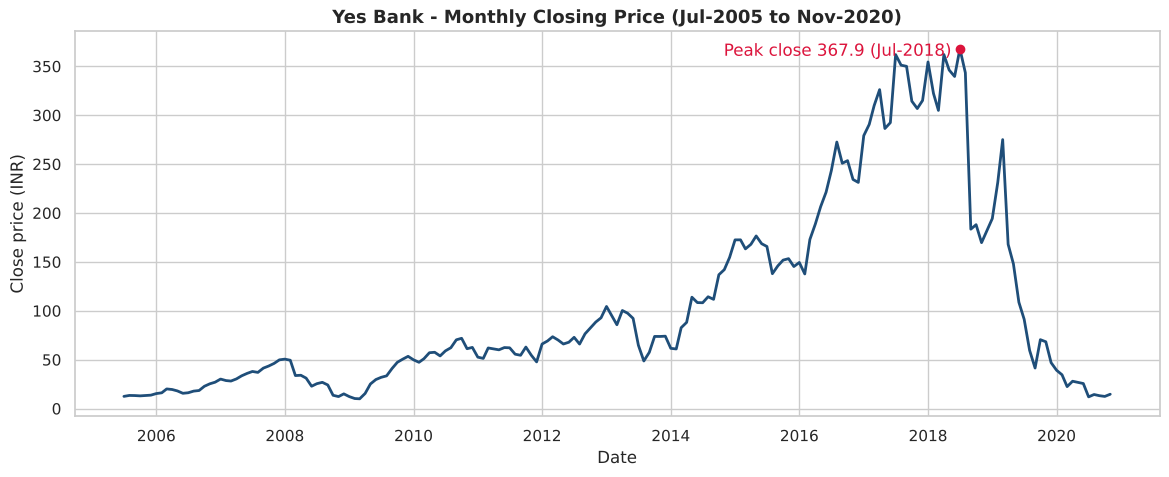

Growth Jul-05 -> peak: 29.7% a year | Last close 14.67 = -96.0% vs the peak


In [ ]:
# Chart - 1 visualization code: closing price over time
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Close"], color="#1f4e79", linewidth=2)
peak = df.loc[df["Close"].idxmax()]
ax.scatter(peak["Date"], peak["Close"], color="crimson", zorder=5)
ax.annotate(f"Peak close {peak['Close']:.1f} ({peak['Date']:%b-%Y})", (peak["Date"], peak["Close"]),
            xytext=(-170, -5), textcoords="offset points", color="crimson")
ax.set(title="Yes Bank - Monthly Closing Price (Jul-2005 to Nov-2020)", xlabel="Date", ylabel="Close price (INR)")
plt.show()

cagr = (peak["Close"] / df["Close"].iloc[0]) ** (1 / ((peak["Date"] - df["Date"].iloc[0]).days / 365.25)) - 1
print(f"Growth Jul-05 -> peak: {cagr:.1%} a year | Last close {df['Close'].iloc[-1]:.2f} = "
      f"{df['Close'].iloc[-1] / peak['Close'] - 1:.1%} vs the peak")

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for one variable that is observed over ordered time: it shows the trend, turning points and regime changes at a glance, which a table or histogram cannot.

##### 2. What is/are the insight(s) found from the chart?

The close grew from 12.46 (Jul-05) to a peak of 367.90 (Jul-18), roughly 30% a year, and then collapsed to 14.67 by Nov-20: about 96% below the peak and only 18% above the starting price after 15 years. Earlier falls (low of 9.98 in Mar-09, 2011, 2013) were recovered within a few years; the post-2018 fall was not.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the 13-year rise shows the franchise created large value, so a recovery story has to rest on governance and capital repair rather than on time alone. **Negative:** the Sep-2018 close alone dropped 46.6% in one month, so one governance shock removed almost half of the value. Event risk of this kind must be monitored explicitly instead of being assumed away.

#### Chart - 2

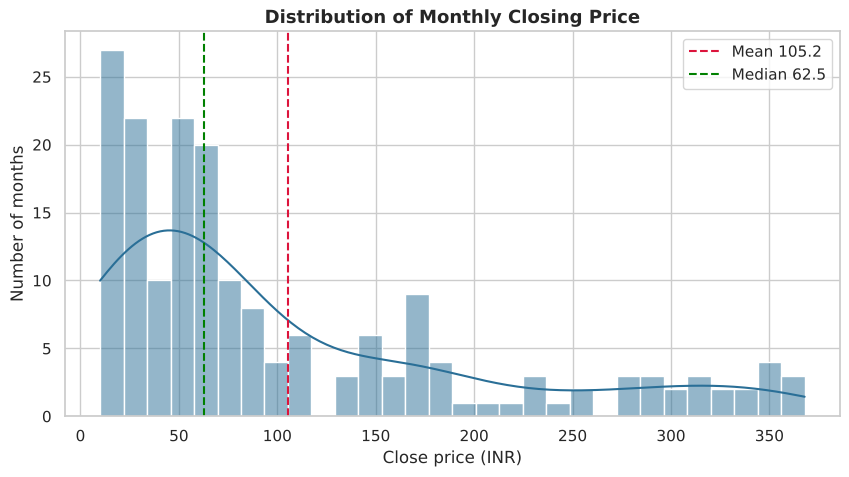

Skewness: 1.26 | months below 50: 68 | months above 250: 24


In [ ]:
# Chart - 2 visualization code: distribution of the closing price
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Close"], bins=30, kde=True, color="#2a6f97", ax=ax)
ax.axvline(df["Close"].mean(), color="crimson", ls="--", label=f"Mean {df['Close'].mean():.1f}")
ax.axvline(df["Close"].median(), color="green", ls="--", label=f"Median {df['Close'].median():.1f}")
ax.set(title="Distribution of Monthly Closing Price", xlabel="Close price (INR)", ylabel="Number of months")
ax.legend()
plt.show()
print(f"Skewness: {df['Close'].skew():.2f} | months below 50: {(df['Close'] < 50).sum()} | months above 250: {(df['Close'] > 250).sum()}")

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape of the distribution, its skewness and the gap between mean and median in one view.

##### 2. What is/are the insight(s) found from the chart?

The distribution is clearly right-skewed (skewness 1.26): the mean (105.2) is far above the median (62.5). 68 of 185 months (37%) closed below 50, while only 24 months (13%) closed above 250 and all of those fall between Aug-2016 and Mar-2019.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing that the price is skewed tells us to model log prices or returns and to quote medians instead of averages. **Negative:** the high-price phase lasted only about two and a half years, so benchmarks based on the average price overstate what a typical month looked like and could mislead valuation or target setting.

#### Chart - 3

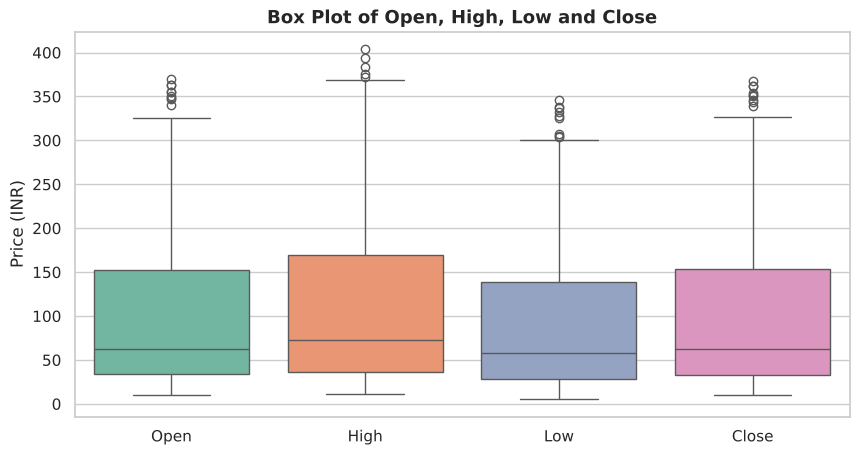

Open  median   63.0 | upper fence  331.8 | outliers: 9 (Aug-17 to Sep-18)
High  median   72.5 | upper fence  368.8 | outliers: 5 (Jul-17 to Aug-18)
Low   median   58.0 | upper fence  303.1 | outliers: 9 (Aug-17 to Aug-18)
Close median   62.5 | upper fence  333.1 | outliers: 9 (Jul-17 to Aug-18)


In [ ]:
# Chart - 3 visualization code: box plot of the four price columns
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[["Open", "High", "Low", "Close"]], ax=ax, palette="Set2")
ax.set(title="Box Plot of Open, High, Low and Close", ylabel="Price (INR)")
plt.show()

for col in ["Open", "High", "Low", "Close"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    out = df[df[col] > upper]
    print(f"{col:<5} median {df[col].median():6.1f} | upper fence {upper:6.1f} | outliers: {len(out)} "
          f"({out['Date'].min():%b-%y} to {out['Date'].max():%b-%y})")

##### 1. Why did you pick the specific chart?

A box plot compares the spread, median and outliers of several numeric columns side by side, which is exactly what is needed to screen all four price columns for data problems.

##### 2. What is/are the insight(s) found from the chart?

The four columns have almost the same shape (medians near 63, upper fences between 303 and 369). The IQR rule marks 9 Open, 5 High, 9 Low and 9 Close values as outliers, and every one of them lies between Jul-2017 and Sep-2018, the bubble-peak months, rather than being scattered randomly.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the outliers are real market history and not data-entry errors, so no correction is needed. **Negative:** these are the months just before the crash; deleting them would hide the most important risk period, so they must stay in the data and the model must cope with them, for example by using relative (ratio) features.

#### Chart - 4

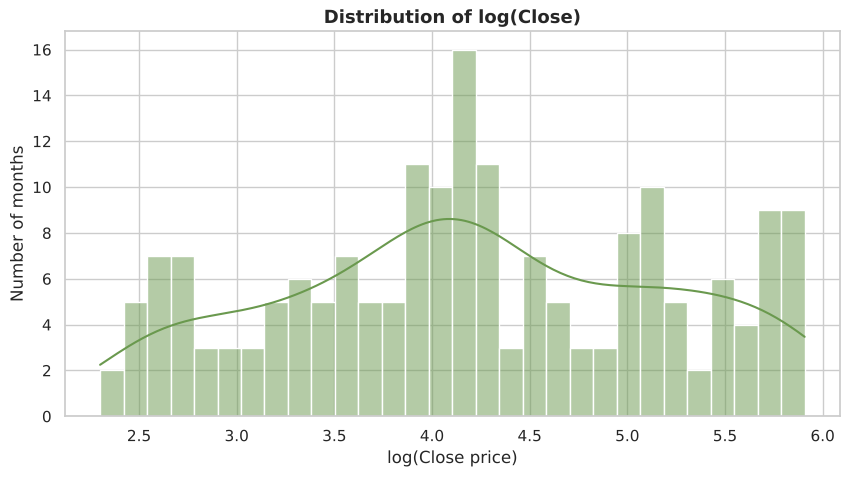

Skewness before log: 1.26 | after log: -0.03


In [ ]:
# Chart - 4 visualization code: log of the closing price
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Log_Close"], bins=30, kde=True, color="#6a994e", ax=ax)
ax.set(title="Distribution of log(Close)", xlabel="log(Close price)", ylabel="Number of months")
plt.show()
print(f"Skewness before log: {df['Close'].skew():.2f} | after log: {df['Log_Close'].skew():.2f}")

##### 1. Why did you pick the specific chart?

After seeing the skew in Chart 2, a histogram of the log-transformed price tests whether a log transformation fixes it.

##### 2. What is/are the insight(s) found from the chart?

The skewness falls from 1.26 to -0.03, so the log price is almost perfectly symmetric. A log scale treats a 10% move the same at a price of 15 and at a price of 300, which the raw price does not.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** log prices (or price ratios) give a more stable basis for modelling and for comparing periods with very different price levels. **Negative:** the log scale hides the absolute loss; the 2018-2020 fall removed about 353 INR per share (367.90 to 14.67), which matters to real investors even though the percentage view looks tidy.

#### Chart - 5

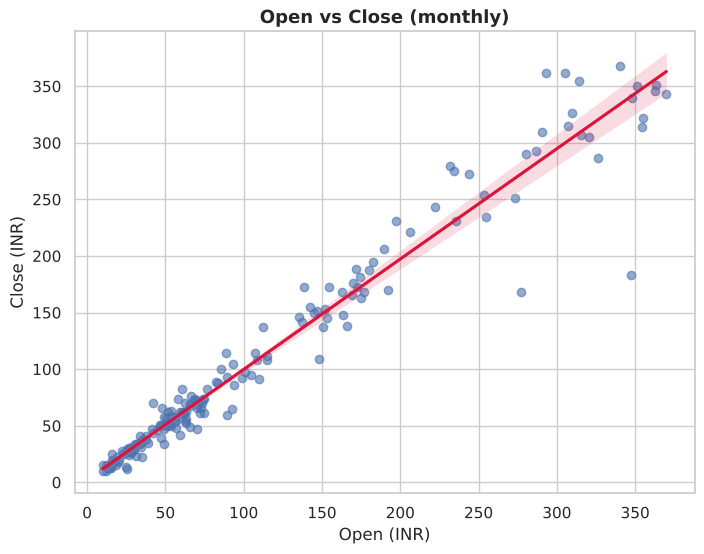

Correlation 0.978 | slope 0.98 | mean |Close/Open - 1| = 11.5%
Std of residuals by price level:
 Close
lowest third      5.7
middle third     10.0
highest third    33.6


In [ ]:
# Chart - 5 visualization code: Open vs Close
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(x="Open", y="Close", data=df, scatter_kws={"alpha": 0.6}, line_kws={"color": "crimson"}, ax=ax)
ax.set(title="Open vs Close (monthly)", xlabel="Open (INR)", ylabel="Close (INR)")
plt.show()

slope, intercept = np.polyfit(df["Open"], df["Close"], 1)
resid = df["Close"] - (slope * df["Open"] + intercept)
terciles = pd.qcut(df["Close"], 3, labels=["lowest third", "middle third", "highest third"])
print(f"Correlation {df['Open'].corr(df['Close']):.3f} | slope {slope:.2f} | mean |Close/Open - 1| = {(df['Close'] / df['Open'] - 1).abs().mean():.1%}")
print("Std of residuals by price level:\n", resid.groupby(terciles).std().round(1).to_string())

##### 1. Why did you pick the specific chart?

A scatter plot with a regression line is the standard way to examine a numeric-numeric relationship, here between the opening price and the closing price.

##### 2. What is/are the insight(s) found from the chart?

The relationship is almost a straight line with slope 0.98 and correlation 0.978. The spread around the line is not constant: the residual standard deviation is 5.7 for the lowest third of prices, 10.0 for the middle third and 33.6 for the highest third. A typical month still moves 11.5% between open and close.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the opening price is a strong anchor for the closing price and a natural model input. **Negative:** the spread widens as prices rise (heteroscedasticity), so absolute errors will always be biggest in high-price months; models should work with ratios or logs so that every period is judged fairly.

#### Chart - 6

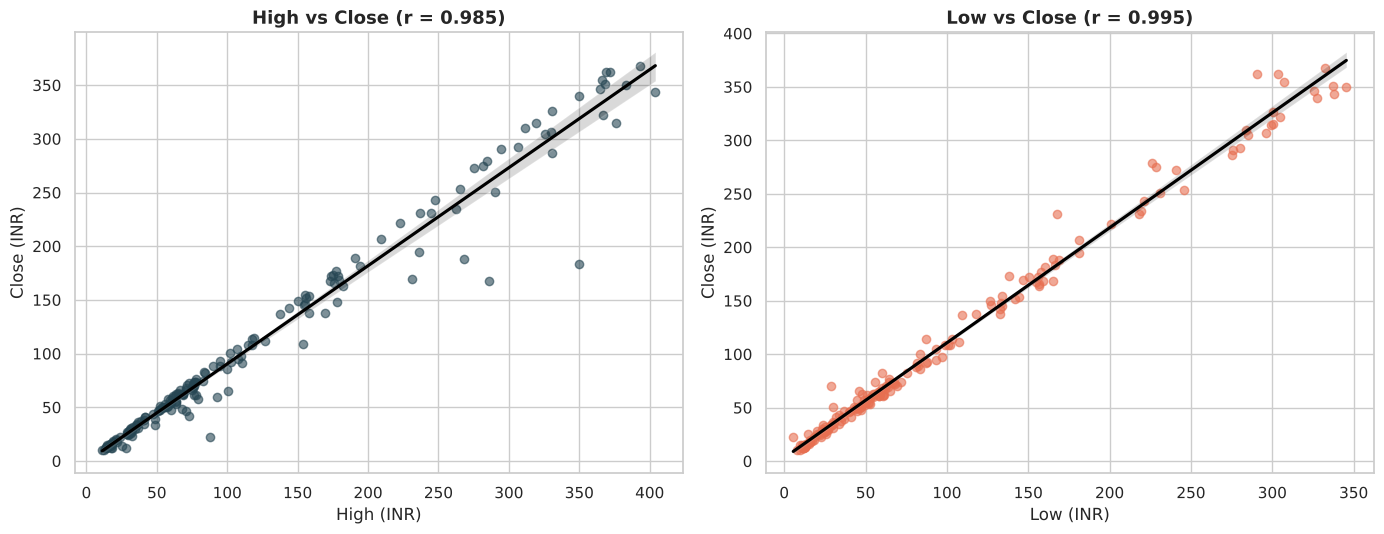

In [ ]:
# Chart - 6 visualization code: High vs Close and Low vs Close
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, color in zip(axes, ["High", "Low"], ["#264653", "#e76f51"]):
    sns.regplot(x=col, y="Close", data=df, scatter_kws={"alpha": 0.6, "color": color}, line_kws={"color": "black"}, ax=ax)
    ax.set(title=f"{col} vs Close (r = {df[col].corr(df['Close']):.3f})", xlabel=f"{col} (INR)", ylabel="Close (INR)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two side-by-side scatter plots with the same y-axis make it easy to compare how tightly the monthly High and the monthly Low track the closing price.

##### 2. What is/are the insight(s) found from the chart?

Both relationships are very tight: Low vs Close has r = 0.995 (the strongest of all pairs) and High vs Close has r = 0.985. The largest departures are crash months where the High is far above the Close, for example Mar-20 (High 87.95, Close 22.45).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** once a month's High and Low are known, the Close can be estimated very accurately, which supports an in-month estimation model. **Negative:** the High and Low of a month are only known at the end of that month, so they cannot be used to forecast the Close of a future month; the business must not confuse estimation with forecasting.

#### Chart - 7

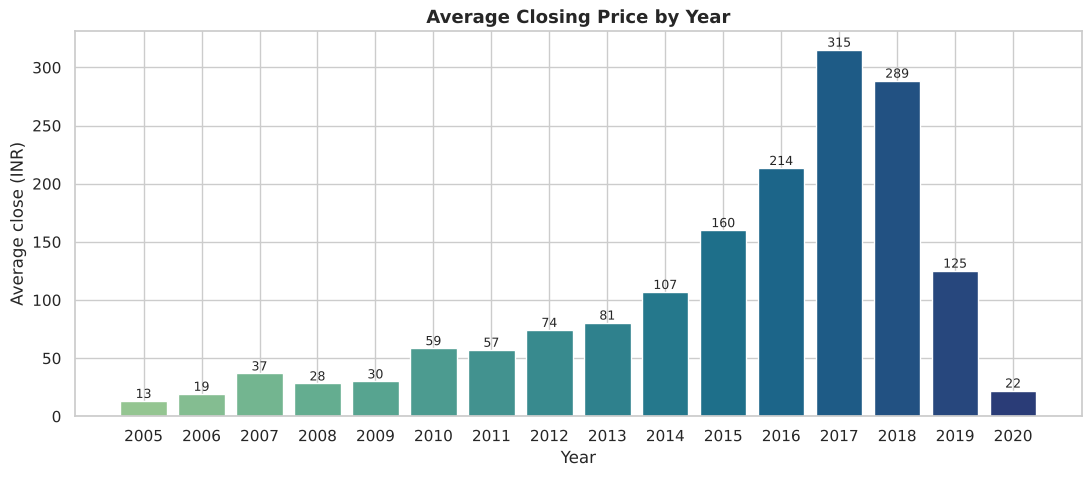

2017 average 315.3 -> 2020 average 22.1 (-93%)


In [ ]:
# Chart - 7 visualization code: average close by year
yearly = df.groupby("Year")["Close"].mean()
fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(yearly.index.astype(str), yearly.values, color=sns.color_palette("crest", len(yearly)))
ax.bar_label(bars, fmt="%.0f", fontsize=9)
ax.set(title="Average Closing Price by Year", xlabel="Year", ylabel="Average close (INR)")
plt.show()
print(f"2017 average {yearly[2017]:.1f} -> 2020 average {yearly[2020]:.1f} ({yearly[2020] / yearly[2017] - 1:.0%})")

##### 1. Why did you pick the specific chart?

A bar chart compares a numeric summary (average price) across a categorical variable (year) and makes level changes between years easy to read.

##### 2. What is/are the insight(s) found from the chart?

The yearly average rises in almost every year from 13.2 (2005) to 315.3 (2017), then falls to 288.6 (2018), 125.3 (2019) and only 22.1 in 2020 (to Nov), roughly the level of 2006. The 2008 and 2011 dips were small compared with the 2019-2020 collapse.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the average price in 2017 was about 24 times that of 2005, evidence of strong long-run value creation. **Negative:** two years (2019-2020) erased 93% of the 2017 average price, so long-term holders of the stock saw a decade of gains disappear.

#### Chart - 8

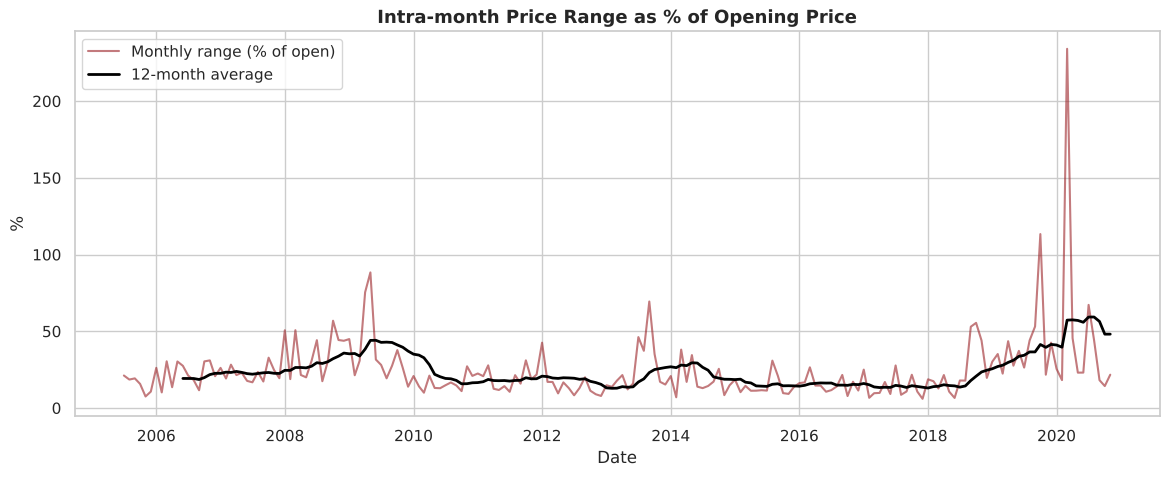

Year
2005    15.5
2006    22.6
2007    22.5
2008    35.8
2009    37.1
2010    16.4
2011    19.1
2012    15.4
2013    26.3
2014    18.7
2015    14.4
2016    15.2
2017    13.5
2018    24.6
2019    41.4
2020    48.6
Largest range: {'Date': Timestamp('2020-03-01 00:00:00'), 'Range_Pct': 234.0909090909091}


In [ ]:
# Chart - 8 visualization code: intra-month range (volatility proxy)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Range_Pct"], color="#9b2226", alpha=0.6, label="Monthly range (% of open)")
ax.plot(df["Date"], df["Range_Pct"].rolling(12).mean(), color="black", linewidth=2, label="12-month average")
ax.set(title="Intra-month Price Range as % of Opening Price", xlabel="Date", ylabel="%")
ax.legend()
plt.show()
print(df.groupby("Year")["Range_Pct"].mean().round(1).to_string())
print("Largest range:", df.loc[df["Range_Pct"].idxmax(), ["Date", "Range_Pct"]].to_dict())

##### 1. Why did you pick the specific chart?

A line chart of the monthly (High minus Low) range, scaled by the open, tracks volatility over time with a measure that is observable every month and comparable across price levels.

##### 2. What is/are the insight(s) found from the chart?

The mean range is 24.3% of the opening price. It was lowest in 2017 (13.5%), had already risen to 24.6% in 2018, and reached 41.4% in 2019 and 48.6% in 2020; the largest single month is Mar-20 at 234%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the range is a simple early-warning indicator: it nearly doubled from 2017 to 2018, before the biggest losses of 2019. **Negative:** with monthly ranges of 40-50% the stock is effectively unusable for risk-averse investors, hedging and liquidity costs rise, and any model errors will be larger in this period.

#### Chart - 9

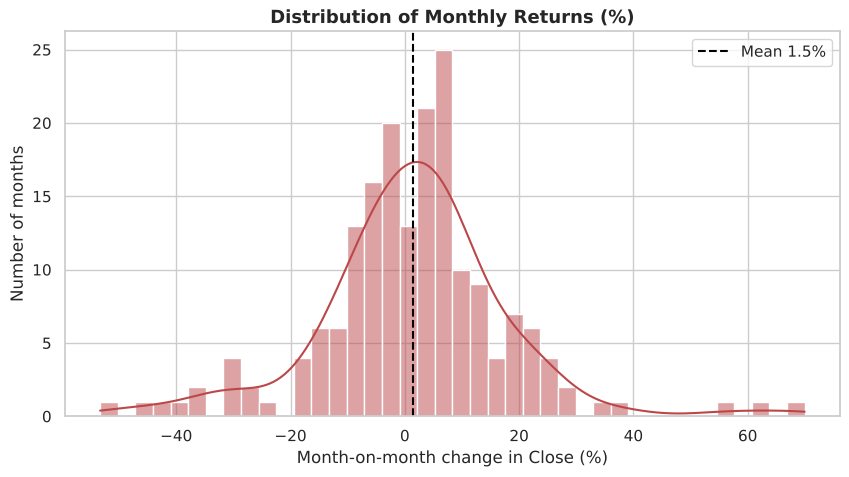

Mean 1.50% | median 2.20% | std 16.53% | excess kurtosis 3.27
Months with |return| > 20%: 31 of 184  (up: 18, down: 13)


In [ ]:
# Chart - 9 visualization code: distribution of monthly returns
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Return"].dropna(), bins=40, kde=True, color="#bc4749", ax=ax)
ax.axvline(df["Return"].mean(), color="black", ls="--", label=f"Mean {df['Return'].mean():.1f}%")
ax.set(title="Distribution of Monthly Returns (%)", xlabel="Month-on-month change in Close (%)", ylabel="Number of months")
ax.legend()
plt.show()
r = df["Return"].dropna()
print(f"Mean {r.mean():.2f}% | median {r.median():.2f}% | std {r.std():.2f}% | excess kurtosis {r.kurt():.2f}")
print(f"Months with |return| > 20%: {(r.abs() > 20).sum()} of {len(r)}  (up: {(r > 20).sum()}, down: {(r < -20).sum()})")

##### 1. Why did you pick the specific chart?

A histogram of returns shows how large and how symmetric the month-to-month moves are, and whether the tails are heavier than a normal distribution.

##### 2. What is/are the insight(s) found from the chart?

The mean monthly return is +1.5% (median +2.2%) but the standard deviation is 16.5%, about 11 times the mean, and the excess kurtosis of 3.3 shows fat tails. 31 of 184 months moved by more than 20% (18 up, 13 down).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** sharp rebounds were possible (+70.0% in Oct-19, +62.6% in May-09). **Negative:** the typical month is dominated by noise, so point forecasts of future prices are inherently uncertain, and fat tails mean that normal-distribution risk estimates understate extreme losses such as the -53.3% in Jul-20.

#### Chart - 10

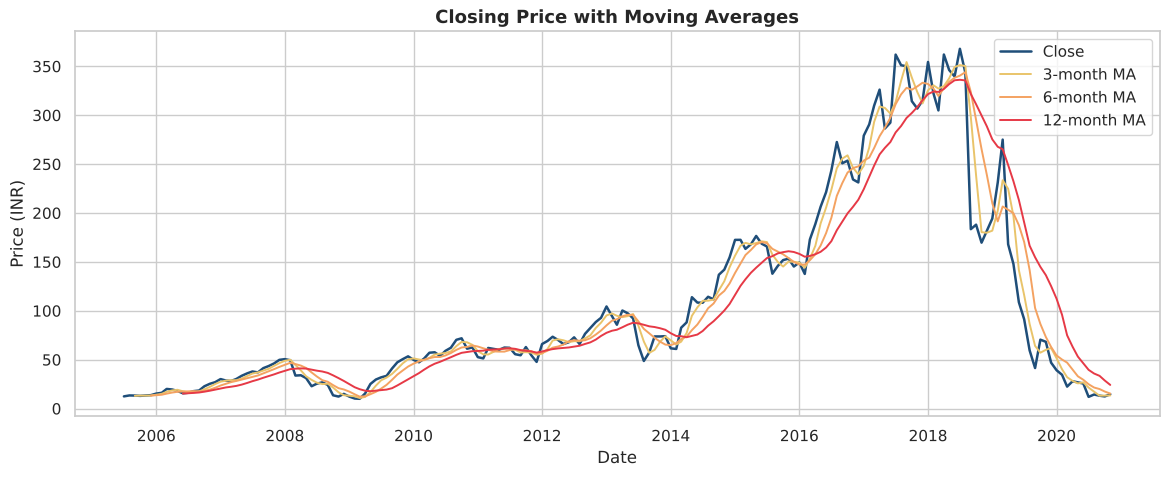

Decline (Sep-18 to Nov-20)  : close below its 12-month average in 26 of 27 months (96%)
Rise (Jul-05 to Aug-18)     : close below its 12-month average in 40 of 147 months (27%)


In [ ]:
# Chart - 10 visualization code: close with 3/6/12-month moving averages
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Close"], label="Close", color="#1f4e79", linewidth=1.8)
for window, color in zip((3, 6, 12), ("#e9c46a", "#f4a261", "#e63946")):
    ax.plot(df["Date"], df[f"MA{window}"], label=f"{window}-month MA", color=color, linewidth=1.4)
ax.set(title="Closing Price with Moving Averages", xlabel="Date", ylabel="Price (INR)")
ax.legend()
plt.show()

valid = df.dropna(subset=["MA12"])
below = valid["Close"] < valid["MA12"]
for era, grp in valid.groupby("Era"):
    print(f"{era:<28}: close below its 12-month average in {below[grp.index].sum()} of {len(grp)} months ({below[grp.index].mean():.0%})")

##### 1. Why did you pick the specific chart?

Moving averages smooth out monthly noise and show the direction of the trend; the project architecture lists them explicitly, and close-versus-average is also a simple rule-based signal.

##### 2. What is/are the insight(s) found from the chart?

In the rise era the close was below its 12-month average in only 27% of months, while after the peak it was below it in 26 of 27 months (96%). The first break below the 12-month average came in Sep-2018, the month of the 46.6% drop.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a simple 'close below the 12-month average' rule marks the regime change immediately and could be used as a trigger to review exposure. **Negative:** the signal arrived at the end of the month in which the price had already fallen from 343 to 183, so moving averages lag and could not have avoided the first loss.

#### Chart - 11

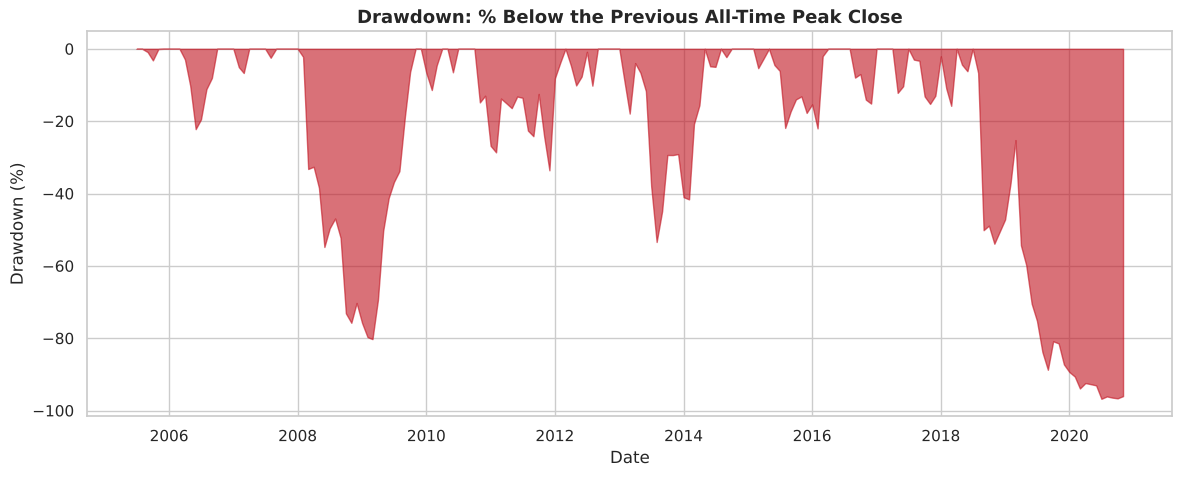

Dec-18: -50.6%
Dec-19: -87.2%
Last month: -96.0%
Deepest: -96.8 % in Jul-2020
First month below -50%: Jun-2008


In [ ]:
# Chart - 11 visualization code: drawdown from the running peak
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(df["Date"], df["Drawdown"], 0, color="#c1121f", alpha=0.6)
ax.set(title="Drawdown: % Below the Previous All-Time Peak Close", xlabel="Date", ylabel="Drawdown (%)")
plt.show()
for label, date in [("Dec-18", "2018-12-01"), ("Dec-19", "2019-12-01"), ("Last month", "2020-11-01")]:
    print(f"{label}: {df.loc[df['Date'] == date, 'Drawdown'].iloc[0]:.1f}%")
print("Deepest:", round(df["Drawdown"].min(), 1), "% in", df.loc[df["Drawdown"].idxmin(), "Date"].strftime("%b-%Y"))
print("First month below -50%:", df.loc[df["Drawdown"] < -50, "Date"].iloc[0].strftime("%b-%Y"))

##### 1. Why did you pick the specific chart?

Drawdown, the distance below the running peak, is the standard way to show risk and 'pain' over time, and it combines price level and history in one multivariate view.

##### 2. What is/are the insight(s) found from the chart?

The drawdown had touched -50% in Jun-2008 (financial crisis) but recovered. After the 2018 peak it reached -50.6% by Dec-18, -87.2% by Dec-19 and bottomed at -96.8% in Jul-20; in the last month it is still -96.0%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the 2008 drawdown recovered within a few years, so past crises show that deep falls can reverse when the fundamentals are repaired. **Negative:** after a 96% fall the price must rise about 25 times (+2,400%) to return to the peak, so a recovery to the old high is unrealistic and goals should be set from the current base.

#### Chart - 12

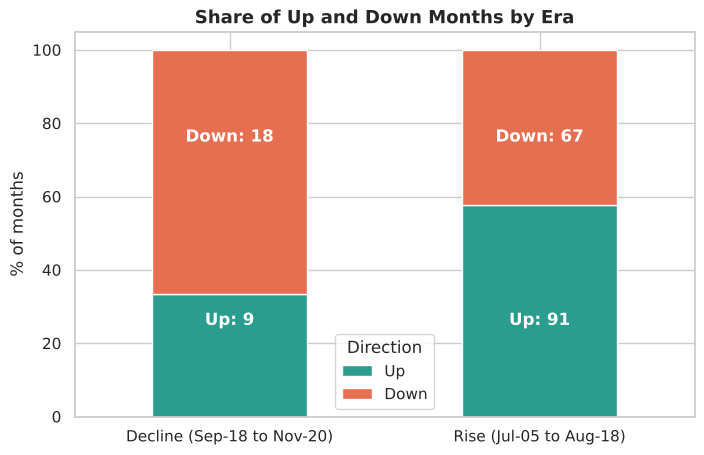

Direction                   Up  Down
Era                                 
Decline (Sep-18 to Nov-20)   9    18
Rise (Jul-05 to Aug-18)     91    67


In [ ]:
# Chart - 12 visualization code: up vs down months by era
counts = pd.crosstab(df["Era"], df["Direction"])[["Up", "Down"]]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
ax = shares.plot(kind="bar", stacked=True, color=["#2a9d8f", "#e76f51"], figsize=(8, 5), rot=0)
for i, (era, row) in enumerate(counts.iterrows()):
    ax.text(i, 25, f"Up: {row['Up']}", ha="center", color="white", fontweight="bold")
    ax.text(i, 75, f"Down: {row['Down']}", ha="center", color="white", fontweight="bold")
ax.set(title="Share of Up and Down Months by Era", xlabel="", ylabel="% of months")
plt.show()
print(counts)

##### 1. Why did you pick the specific chart?

A stacked bar chart is the clearest way to compare the proportion of a categorical outcome (up month vs down month) across two categories (eras).

##### 2. What is/are the insight(s) found from the chart?

In the rise era 91 of 158 months were up months (58%). In the decline era only 9 of 27 were up (33%) and 18 were down months.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** in the rise era the odds favoured the holder: more than half of the months were positive. **Negative:** in the decline era two of every three months lost money, a persistent negative momentum which shows that buy-and-hold was punished, and which no single good month could repair.

#### Chart - 13

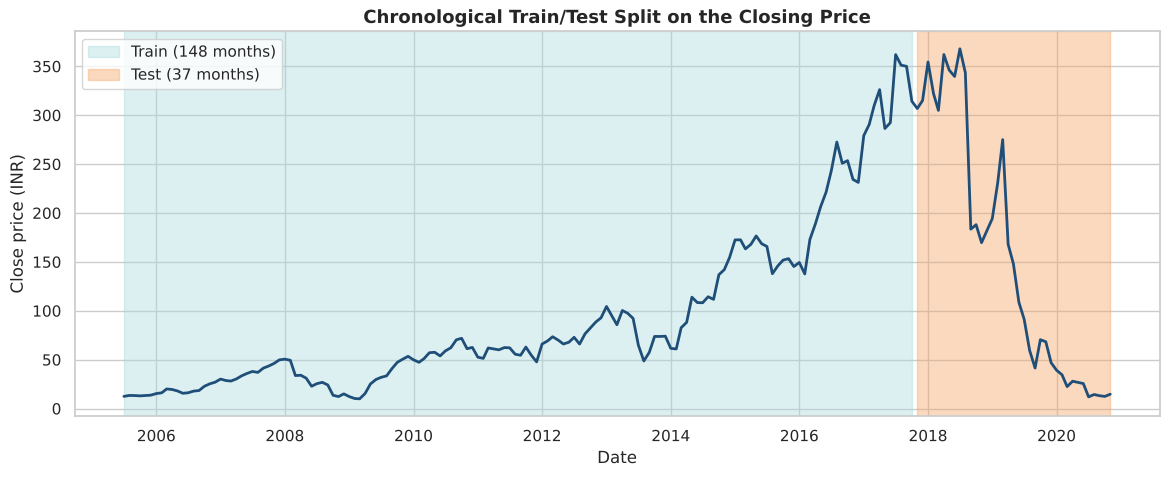

Train close range 9.98 - 361.96 | test close range 11.95 - 367.90
Test months contain the all-time peak (367.90) and the crash to 14.67


In [ ]:
# Chart - 13 visualization code: where the chronological train/test split falls
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Close"], color="#1f4e79", linewidth=2)
ax.axvspan(df["Date"].iloc[0], df["Date"].iloc[split_idx - 1], color="#a8dadc", alpha=0.4, label=f"Train ({split_idx} months)")
ax.axvspan(df["Date"].iloc[split_idx], df["Date"].iloc[-1], color="#f4a261", alpha=0.4, label=f"Test ({len(df) - split_idx} months)")
ax.set(title="Chronological Train/Test Split on the Closing Price", xlabel="Date", ylabel="Close price (INR)")
ax.legend(loc="upper left")
plt.show()
train_close, test_close = df["Close"].iloc[:split_idx], df["Close"].iloc[split_idx:]
print(f"Train close range {train_close.min():.2f} - {train_close.max():.2f} | test close range {test_close.min():.2f} - {test_close.max():.2f}")
print(f"Test months contain the all-time peak ({test_close.max():.2f}) and the crash to {test_close.iloc[-1]:.2f}")

##### 1. Why did you pick the specific chart?

A line chart with shaded train and test periods shows exactly which part of the history the models learn from and which part they are judged on.

##### 2. What is/are the insight(s) found from the chart?

The first 148 months (Jul-05 to Oct-17, close 9.98 to 361.96) are used for training and the last 37 months (Nov-17 to Nov-20, close 11.95 to 367.90) for testing. The test period contains the all-time peak and the whole crash, so it is a hard stress test rather than an easy average period.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a model that scores well on this test has been validated on the most dangerous part of the history, so the result is credible. **Negative:** the headline errors in rupees will be dominated by the 2018-2019 months when prices were high and swinging wildly, so error should also be read as a percentage and per period.

#### Chart - 14 - Correlation Heatmap

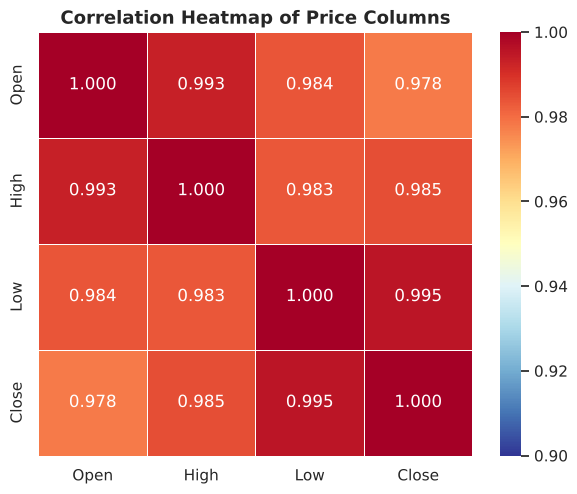

VIF: {'Open': np.float64(81.9), 'High': np.float64(79.2), 'Low': np.float64(34.6)} (above 10 signals serious multicollinearity)


In [ ]:
# Correlation Heatmap visualization code
price_cols = ["Open", "High", "Low", "Close"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[price_cols].corr(), annot=True, fmt=".3f", cmap="RdYlBu_r", vmin=0.9, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Price Columns")
plt.show()

# Variance Inflation Factor: how strongly each predictor is explained by the other predictors
X = np.column_stack([np.ones(len(df)), df[["Open", "High", "Low"]].values])
vif = {c: variance_inflation_factor(X, i + 1) for i, c in enumerate(["Open", "High", "Low"])}
print("VIF:", {k: round(v, 1) for k, v in vif.items()}, "(above 10 signals serious multicollinearity)")

##### 1. Why did you pick the specific chart?

A heatmap condenses all pairwise correlations into one matrix, so strong relationships and the best candidate predictors are visible immediately.

##### 2. What is/are the insight(s) found from the chart?

All pairs are above 0.97: Close-Low 0.995 is the highest, Open-High 0.993, Close-High 0.985 and Close-Open 0.978. The variance inflation factors of Open, High and Low as predictors (about 82, 79 and 35) are far above the usual limit of 10, which means severe multicollinearity.

#### Chart - 15 - Pair Plot

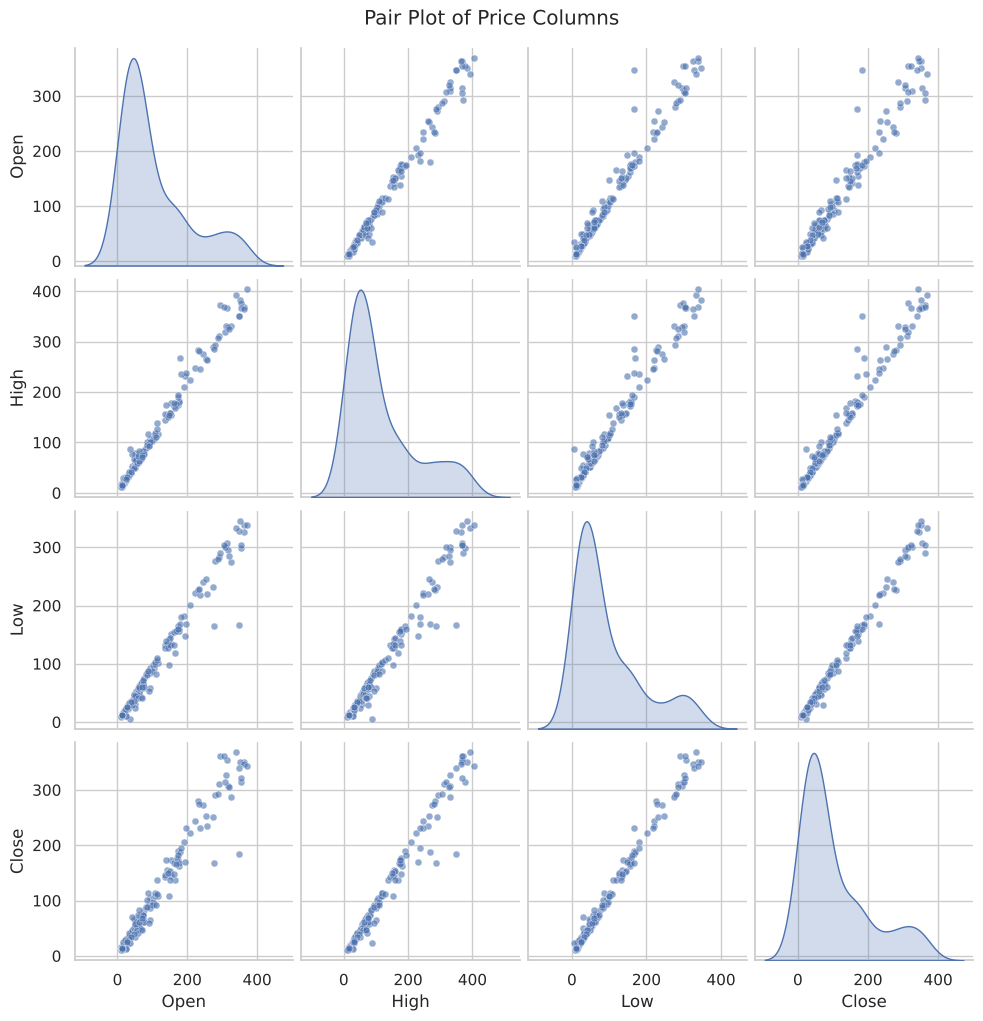

In [ ]:
# Pair Plot visualization code
sns.pairplot(df[["Open", "High", "Low", "Close"]], diag_kind="kde", plot_kws={"alpha": 0.6, "s": 25})
plt.suptitle("Pair Plot of Price Columns", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plot and each variable's distribution together, which checks linearity and spread beyond what a single correlation number can say.

##### 2. What is/are the insight(s) found from the chart?

All relationships are close to linear lines through the origin, but the cloud becomes a fan: the spread widens at higher prices (the same heteroscedasticity seen in Chart 5). Every diagonal density is right-skewed with a similar shape, so the four prices behave as near copies of one another.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

The charts suggest three statements that can be tested statistically:

1. **Chart 1, 10, 12:** the stock rose until Aug-2018 and fell afterwards, so the *mean monthly return* should differ between the rise era and the decline era.
2. **Chart 8 and 13:** monthly ranges look wider after 2018, so *volatility* (the intra-month range) should be higher in the decline era.
3. **Chart 9 and 10:** moves look random from one month to the next, so *monthly returns should have no autocorrelation*. This is the statement that decides whether next month can be forecast from last month.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Statement 1: the average monthly return is different before and after the Aug-2018 peak.**
* H0: the mean monthly log return is the same in the rise era and the decline era (mu_rise = mu_decline).
* H1: the mean monthly log return is different (mu_rise != mu_decline).

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Statement 1: mean monthly log return, rise era vs decline era)
rise = df.loc[df["Era"].str.startswith("Rise"), "Log_Return"].dropna()
decline = df.loc[df["Era"].str.startswith("Decline"), "Log_Return"].dropna()

t_stat, p_welch = stats.ttest_ind(rise, decline, equal_var=False)               # Welch t-test (unequal variances)
u_stat, p_mw = stats.mannwhitneyu(rise, decline, alternative="two-sided")       # robustness check (returns are not normal)
print(f"Mean log return: rise era {rise.mean():+.2%} (n={len(rise)}) | decline era {decline.mean():+.2%} (n={len(decline)})")
print(f"Welch t-test      : t = {t_stat:.3f}, p-value = {p_welch:.4f}")
print(f"Mann-Whitney U    : U = {u_stat:.0f}, p-value = {p_mw:.4f}")
print("Decision at 5% level:", "reject H0" if p_welch < 0.05 else "fail to reject H0")

Mean log return: rise era +2.11% (n=157) | decline era -11.68% (n=27)
Welch t-test      : t = 2.438, p-value = 0.0214
Mann-Whitney U    : U = 2825, p-value = 0.0058
Decision at 5% level: reject H0


##### Which statistical test have you done to obtain P-Value?

**Welch's two-sample t-test** (p-value = 0.0214), cross-checked with the **Mann-Whitney U test** (p-value = 0.0058). Both reject H0 at the 5% level: the mean monthly log return was +2.11% in the rise era (157 months) and -11.68% in the decline era (27 months).

*Caveat:* the split date (the Aug-2018 peak) was chosen after looking at the data, so the p-values are somewhat optimistic; the economic difference is very large, however.

##### Why did you choose the specific statistical test?

The two eras are independent groups of very different size (157 vs 27 months) and clearly different variance (monthly standard deviation about 13% vs 29%), so Welch's t-test, which does not assume equal variances, is the appropriate parametric test. Returns are not normally distributed (fat tails, Shapiro-Wilk p < 0.001) and the decline group is small, so the non-parametric Mann-Whitney U test was added as a robustness check. Both tests agree.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Statement 2: the intra-month price range (a volatility measure) is higher in the decline era.**
* H0: the distribution of the range (High minus Low, as % of Open) is the same in both eras.
* H1: range values in the rise era are smaller than in the decline era.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Statement 2: intra-month range, rise era vs decline era)
range_rise = df.loc[df["Era"].str.startswith("Rise"), "Range_Pct"]
range_decline = df.loc[df["Era"].str.startswith("Decline"), "Range_Pct"]

u_stat, p_value = stats.mannwhitneyu(range_rise, range_decline, alternative="less")   # H1: rise-era ranges are smaller
print(f"Median range: rise era {range_rise.median():.1f}% | decline era {range_decline.median():.1f}% of the open")
print(f"Mann-Whitney U = {u_stat:.0f}, one-sided p-value = {p_value:.2e}")
print("Decision at 5% level:", "reject H0" if p_value < 0.05 else "fail to reject H0")

Median range: rise era 17.5% | decline era 35.2% of the open
Mann-Whitney U = 783, one-sided p-value = 7.69e-08
Decision at 5% level: reject H0


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test** (one-sided), p-value = 7.7e-08. H0 is rejected at the 5% level: the median monthly range was 17.5% of the open in the rise era and 35.2% in the decline era, i.e. about twice as high.

##### Why did you choose the specific statistical test?

The range is strongly skewed with extreme values (up to 234% in Mar-2020), so a rank-based test is safer than a t-test. The two samples are independent, and the one-sided alternative matches the hypothesis that volatility *increased* after the peak.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Statement 3: monthly returns have no memory: last month's return does not help to predict this month's return.**
* H0: the lag-1 autocorrelation of monthly log returns is zero (rho = 0).
* H1: the lag-1 autocorrelation is not zero (rho != 0).

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Statement 3: monthly returns have no lag-1 autocorrelation)
r = df["Log_Return"].dropna()
rho, p_rho = stats.pearsonr(r.iloc[1:].values, r.iloc[:-1].values)
lb = acorr_ljungbox(r, lags=[1, 6, 12], return_df=True)
print(f"Lag-1 autocorrelation of monthly log returns: rho = {rho:.3f}, p-value = {p_rho:.4f}")
print("Ljung-Box test (H0: no autocorrelation up to the given lag):")
display(lb.round(4))
print("Decision at 5% level:", "reject H0" if p_rho < 0.05 else "fail to reject H0")

Lag-1 autocorrelation of monthly log returns: rho = 0.133, p-value = 0.0724
Ljung-Box test (H0: no autocorrelation up to the given lag):


,lb_stat,lb_pvalue
1,3.2959,0.0695
6,5.9724,0.4263
12,14.9559,0.2439


Decision at 5% level: fail to reject H0


##### Which statistical test have you done to obtain P-Value?

**Pearson correlation test** between each month's log return and the previous month's (rho = 0.133, p-value = 0.0724) and the **Ljung-Box test** (p-values 0.0695, 0.4263 and 0.2439 at lags 1, 6 and 12). H0 cannot be rejected at the 5% level: there is no statistically significant evidence that returns can be predicted from the past, although lag 1 is borderline.

##### Why did you choose the specific statistical test?

The correlation test answers the question directly for one lag, and the Ljung-Box test checks several lags jointly so that we do not miss a pattern at lag 6 or 12. The result matters for the project: it predicts that models using past prices to forecast next month will struggle, which the forecasting check in the model section confirms.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [ ]:
# Handling Missing Values & Missing Value Imputation
print("Missing values in the raw data:")
print(raw.isnull().sum().to_string())
# Rolling/lagged features are undefined in the first rows. We never impute prices or the target:
print("\nNaN created by rolling features:", df[["Log_Return", "MA12", "Vol12"]].isnull().sum().to_dict())

Missing values in the raw data:
Date     0
Open     0
High     0
Low      0
Close    0

NaN created by rolling features: {'Log_Return': 1, 'MA12': 11, 'Vol12': 12}


#### What all missing value imputation techniques have you used and why did you use those techniques?

**No imputation technique was needed:** the raw data contain no missing values. The only NaN values are created by rolling features in the first rows (1 for the return, 11 for the 12-month average, 12 for the 12-month volatility). Those features are not model inputs. For the lagged forecasting check the first rows are dropped, not imputed, because filling them would either invent prices or use future information. The target is never imputed.

### 2. Handling Outliers

In [ ]:
# Handling Outliers & Outlier treatments
def iqr_report(series, label):
    q1, q3 = series.quantile([0.25, 0.75])
    low_f, up_f = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    out = series[(series < low_f) | (series > up_f)]
    dates = df.loc[out.index, "Date"]
    span = f"{dates.min():%b-%y} to {dates.max():%b-%y}" if len(out) else "-"
    print(f"{label:<12} outliers: {len(out):>2} | {span}")

for col in ["Open", "High", "Low", "Close"]:
    iqr_report(df[col], col)
iqr_report(df["Return"].dropna(), "Return (%)")
print("\nDecision: outliers are kept (no capping or deletion).")

Open         outliers:  9 | Aug-17 to Sep-18
High         outliers:  5 | Jul-17 to Aug-18
Low          outliers:  9 | Aug-17 to Aug-18
Close        outliers:  9 | Jul-17 to Aug-18
Return (%)   outliers: 15 | Mar-08 to Jul-20

Decision: outliers are kept (no capping or deletion).


##### What all outlier treatment techniques have you used and why did you use those techniques?

**No outlier treatment was applied.** The IQR rule flags 5 to 9 values in each price column, all between Jul-2017 and Sep-2018, and 15 monthly returns between Mar-2008 and Jul-2020. They are real market events (the bubble peak and the crashes), not data errors. Deleting or capping them would remove exactly the months the model is supposed to handle and would make the test results look better than they are. Instead, robustness comes from using relative (ratio) features, and the models are evaluated separately on calm and crash months.

### 3. Categorical Encoding

In [ ]:
# Encode your categorical columns
non_numeric = [c for c in df.columns
               if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c])]
print("Non-numeric columns:", non_numeric)
for col in non_numeric:
    print(f"  {col:<10} values: {sorted(df[col].unique())[:12]}")
print("\nNone of them is a model input, so no encoding is applied (reasons in the text below).")

Non-numeric columns: ['Month_Name', 'Direction', 'Era']
  Month_Name values: ['Apr', 'Aug', 'Dec', 'Feb', 'Jan', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
  Direction  values: ['Down', 'Up']
  Era        values: ['Decline (Sep-18 to Nov-20)', 'Rise (Jul-05 to Aug-18)']

None of them is a model input, so no encoding is applied (reasons in the text below).


#### What all categorical encoding techniques have you used & why did you use those techniques?

**No encoding was needed.** The only non-numeric columns are `Month_Name`, `Direction` and `Era`, and none of them is a model input: `Direction` is computed from Close and Open (it would leak the target), `Era` is defined by the 2018 peak, which is only known afterwards (look-ahead), and calendar month has no significant effect on returns (Kruskal-Wallis p = 0.34 in the EDA). If month dummies were ever needed, one-hot encoding with 11 columns would be used.

**Not applicable.** This is a numeric price dataset with no text column, so the 10 text-preprocessing steps (contraction expansion, lower casing, punctuation and stop-word removal, tokenization, lemmatization, POS tagging and vectorization) are not used.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [ ]:
# Manipulate Features to minimize feature correlation and create new features
def vif_table(frame, cols):
    """Variance Inflation Factor of each predictor (above 10 = serious multicollinearity)."""
    X = np.column_stack([np.ones(len(frame)), frame[cols].values])
    return pd.Series({c: variance_inflation_factor(X, i + 1) for i, c in enumerate(cols)}).round(1)

def add_model_features(frame):
    """Scale-free features: log(High/Open), log(Low/Open) and the target log(Close/Open)."""
    f = frame.copy()
    f["High_Rel"] = np.log(f["High"] / f["Open"])
    f["Low_Rel"] = np.log(f["Low"] / f["Open"])
    f["Target_Rel"] = np.log(f["Close"] / f["Open"])
    f["Log_Open"] = np.log(f["Open"])
    return f

def to_price(open_price, rel_pred):
    """Convert a predicted log(Close/Open) back into a closing price in INR."""
    return np.asarray(open_price, dtype=float) * np.exp(rel_pred)

model_df = add_model_features(df)
print("VIF with raw prices       :", vif_table(model_df, ["Open", "High", "Low"]).to_dict())
print("VIF with relative features:", vif_table(model_df, ["High_Rel", "Low_Rel"]).to_dict())
display(model_df[["High_Rel", "Low_Rel", "Target_Rel"]].corr().round(3))

VIF with raw prices       : {'Open': 81.9, 'High': 79.2, 'Low': 34.6}
VIF with relative features: {'High_Rel': 1.0, 'Low_Rel': 1.0}


,High_Rel,Low_Rel,Target_Rel
High_Rel,1.000,-0.170,0.455
Low_Rel,-0.170,1.000,0.706
Target_Rel,0.455,0.706,1.000


#### 2. Feature Selection

In [ ]:
# Select your features wisely to avoid overfitting
def price_cv_scores(feature_cols, target_col, n_splits=5):
    """Expanding-window CV on the TRAINING months only; errors are always measured on the Close in INR."""
    train = model_df.iloc[:split_idx]
    rmses, mapes = [], []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=n_splits).split(train):
        tr, va = train.iloc[tr_idx], train.iloc[va_idx]
        mdl = LinearRegression().fit(tr[feature_cols], tr[target_col])
        pred = mdl.predict(va[feature_cols])
        pred_price = to_price(va["Open"], pred) if target_col == "Target_Rel" else pred
        rmses.append(np.sqrt(mean_squared_error(va["Close"], pred_price)))
        mapes.append(np.mean(np.abs(pred_price / va["Close"] - 1)) * 100)
    return np.mean(rmses), np.mean(mapes)

candidates = {
    "A: Open, High, Low -> Close": (["Open", "High", "Low"], "Close"),
    "B: High_Rel, Low_Rel -> log(Close/Open)": (["High_Rel", "Low_Rel"], "Target_Rel"),
    "C: B + Log_Open": (["High_Rel", "Low_Rel", "Log_Open"], "Target_Rel"),
}
rows = []
for name, (cols, target) in candidates.items():
    rmse, mape = price_cv_scores(cols, target)
    rows.append({"Feature set": name, "CV RMSE (INR)": rmse, "CV MAPE (%)": mape})
display(pd.DataFrame(rows).round(2))

# Final choice (explained below)
FEATURES = ["High_Rel", "Low_Rel"]
TARGET = "Target_Rel"

,Feature set,CV RMSE (INR),CV MAPE (%)
0,"A: Open, High, Low -> Close",5.34,5.45
1,"B: High_Rel, Low_Rel -> log(Close/Open)",4.61,4.69
2,C: B + Log_Open,5.24,5.32


##### What all feature selection methods have you used  and why?

Three complementary methods were used:
1. **Domain logic / leakage check:** only same-month High and Low are legitimate inputs next to Open. `Direction`, the moving averages, `Gap_vs_MA6`, `Drawdown` and `Era` use the month's Close or future information and were excluded.
2. **Multicollinearity (VIF):** raw Open/High/Low have VIFs of 82, 79 and 35, while the relative features have VIFs of 1.0.
3. **Time-series cross-validation on the training months only** compared three feature sets with Linear Regression. Set B (High_Rel, Low_Rel) was best with CV RMSE 4.61 INR and MAPE 4.69%, ahead of raw prices (A: 5.34 INR, 5.45%) and B plus Log_Open (C: 5.24 INR, 5.32%). Adding the price level did not help.

Only two features are kept. With 148 training rows, a small feature set also lowers the risk of overfitting.

##### Which all features you found important and why?

**High_Rel = log(High/Open)** and **Low_Rel = log(Low/Open)**: how far the month's high and low are from the open. Both correlate clearly with the target log(Close/Open) (Low_Rel 0.706, High_Rel 0.455) and are almost uncorrelated with each other (-0.170). Their importance is confirmed later: Low_Rel is the more important of the two in the permutation test and in both tree models, partly because it varies more (standard deviation 0.19 against 0.12).

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [ ]:
# Transform Your data
print(f"Skewness of Close: {df['Close'].skew():.2f}  ->  log(Close): {df['Log_Close'].skew():.2f}")
adf_close = adfuller(df["Close"])
adf_ret = adfuller(df["Log_Return"].dropna())
print(f"ADF stationarity test p-value: Close = {adf_close[1]:.3f} (non-stationary) | log return = {adf_ret[1]:.2e} (stationary)")
display(model_df[["High_Rel", "Low_Rel", "Target_Rel"]].describe().round(3))

Skewness of Close: 1.26  ->  log(Close): -0.03
ADF stationarity test p-value: Close = 0.329 (non-stationary) | log return = 1.29e-21 (stationary)


,High_Rel,Low_Rel,Target_Rel
count,185.000,185.000,185.000
mean,0.117,-0.132,-0.004
std,0.119,0.193,0.172
min,0.000,-1.847,-0.762
25%,0.040,-0.152,-0.068
50%,0.085,-0.083,0.011
75%,0.153,-0.030,0.084
max,0.916,0.000,0.517


**Yes.** The data are transformed with logarithmic ratios for three reasons: (1) the raw price is right-skewed (skewness 1.26, against -0.03 after the log transformation); (2) the Close is non-stationary (ADF p = 0.329) while log returns are stationary (p about 1e-21); (3) ratios are scale-free, so one relationship can describe a price of 12 and a price of 360, whereas with raw prices the error spread triples between low and high price levels (EDA, Chart 8). Predictions are converted back with Close = Open x exp(prediction).

### 6. Data Scaling

In [ ]:
# Scaling your data  (the scaler is fitted on the training months only, so nothing leaks from the test period)
scaler_demo = StandardScaler().fit(model_df.iloc[:split_idx][FEATURES])
scaled_train = scaler_demo.transform(model_df.iloc[:split_idx][FEATURES])
scaled_test = scaler_demo.transform(model_df.iloc[split_idx:][FEATURES])
print("Scaled train mean:", scaled_train.mean(axis=0).round(3), "| std:", scaled_train.std(axis=0).round(3))
print("Scaled test  mean:", scaled_test.mean(axis=0).round(3), "| std:", scaled_test.std(axis=0).round(3))

Scaled train mean: [0. 0.] | std: [1. 1.]
Scaled test  mean: [ 0.398 -1.17 ] | std: [1.873 2.828]


##### Which method have you used to scale you data and why?

**StandardScaler** (zero mean, unit variance), fitted on the training months only and placed inside a Pipeline for the Ridge model so that no information from the test period leaks into the model. Scaling matters for Ridge because its penalty treats all coefficients equally; plain Linear Regression, Random Forest and Gradient Boosting do not need it. The output also shows that the test features are 2 to 3 times more dispersed than the training features (scaled standard deviations 1.87 and 2.83): the test period is more volatile than anything the models saw in training.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**No.** There are only two features, their VIFs are 1.0, and PCA shows that both components carry information (65% and 35% of the variance), so dropping one would throw away about a third of the information. Dimensionality reduction would also make the model harder to interpret.

In [ ]:
# Dimensionality Reduction (shown only to confirm it is not needed)
pca = PCA().fit(scaled_train)
print("Explained variance ratio of the principal components:", pca.explained_variance_ratio_.round(3))

Explained variance ratio of the principal components: [0.65 0.35]


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Not applied (see the answer above). PCA was only run to confirm that it is not needed.

### 8. Data Splitting

In [ ]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Chronological split: the model is trained on the past and tested on the future (no shuffling).
train_df, test_df = model_df.iloc[:split_idx], model_df.iloc[split_idx:]
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
open_test, close_test = test_df["Open"], test_df["Close"]      # needed to convert predictions back to INR
test_dates = test_df["Date"]

print(f"Train: {len(train_df)} months ({train_df['Date'].iloc[0]:%b-%Y} to {train_df['Date'].iloc[-1]:%b-%Y})")
print(f"Test : {len(test_df)} months ({test_df['Date'].iloc[0]:%b-%Y} to {test_df['Date'].iloc[-1]:%b-%Y})")

Train: 148 months (Jul-2005 to Oct-2017)
Test : 37 months (Nov-2017 to Nov-2020)


##### What data splitting ratio have you used and why?

**80% / 20% in chronological order:** 148 months for training (Jul-2005 to Oct-2017) and 37 months for testing (Nov-2017 to Nov-2020). A random split was rejected because it would train on months that come after some test months (a leak of the future into the past) and would flatter the scores. The 80/20 ratio leaves enough months to learn from while keeping a test period that contains both the all-time peak and the crash. Inside the training data, 5 expanding time-series folds are used for cross-validation and tuning.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**No.** Imbalance is a classification problem; here the target is a continuous price. (The share of up and down months is 54% / 46%, and it is not a target in any case.)

In [ ]:
# Handling Imbalanced Dataset (If needed)
# The target is a continuous price, so class imbalance does not exist. For reference only:
print(df["Direction"].value_counts(normalize=True).round(3).to_dict(), "(up/down months, not used as a target)")

{'Up': 0.541, 'Down': 0.459} (up/down months, not used as a target)


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No balancing technique was needed.

## ***7. ML Model Implementation***

In [ ]:
# Evaluation helpers shared by all models
results = []          # one row per fitted model; printed and charted at the end

def regression_metrics(close_true, close_pred, n_features):
    """R2, adjusted R2, RMSE, MAE (INR) and MAPE (%) of the predicted closing prices."""
    n = len(close_true)
    r2 = r2_score(close_true, close_pred)
    return {"R2": r2,
            "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - n_features - 1),
            "RMSE": np.sqrt(mean_squared_error(close_true, close_pred)),
            "MAE": mean_absolute_error(close_true, close_pred),
            "MAPE_%": np.mean(np.abs(np.asarray(close_pred) / np.asarray(close_true) - 1)) * 100}

def score_model(name, model):
    """Predict the test months with a fitted model, convert to INR and store the scores."""
    pred_price = to_price(open_test, model.predict(X_test))
    scores = regression_metrics(close_test, pred_price, len(FEATURES))
    results.append({"Model": name, **scores})
    return pred_price, scores

def plot_scores(name, pred_price, scores):
    """Actual vs predicted closing price on the test months, plus the error scores."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2.3, 1]})
    axes[0].plot(test_dates, close_test, label="Actual", color="#1f4e79", marker="o", ms=3)
    axes[0].plot(test_dates, pred_price, label="Predicted", color="#e63946", marker="o", ms=3)
    axes[0].set(title=f"{name}: actual vs predicted Close (test months)", ylabel="INR")
    axes[0].legend()
    axes[1].bar(["RMSE", "MAE"], [scores["RMSE"], scores["MAE"]], color=["#457b9d", "#a8dadc"])
    for i, v in enumerate([scores["RMSE"], scores["MAE"]]):
        axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom")
    axes[1].set(title=f"R2 = {scores['R2']:.4f} | MAPE = {scores['MAPE_%']:.1f}%", ylabel="Error (INR)")
    plt.tight_layout()
    plt.show()

def tune(name, estimator, grid):
    """Grid search with expanding-window (time-series) cross-validation on the training months."""
    search = GridSearchCV(estimator, grid, cv=TimeSeriesSplit(n_splits=5),
                          scoring="neg_root_mean_squared_error", n_jobs=1)
    search.fit(X_train, y_train)
    print(f"{name}: best parameters {search.best_params_} | CV RMSE (log-ratio) = {-search.best_score_:.4f}")
    return search

### ML Model - 1

In [ ]:
# ML Model - 1 Implementation: Linear Regression

# Benchmark with no model at all: predict that the month closes at its opening price
baseline_pred = to_price(open_test, np.zeros(len(open_test)))
results.append({"Model": "Benchmark: Close = Open", **regression_metrics(close_test, baseline_pred, 0)})

# Fit the Algorithm
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict on the model
lr_pred, lr_scores = score_model("Linear Regression", lr)
print("Coefficients:", dict(zip(FEATURES, lr.coef_.round(3))), "| intercept:", round(lr.intercept_, 4))
display(pd.DataFrame(results).set_index("Model").round(4))

Coefficients:

 {'High_Rel': np.float64(0.786), 'Low_Rel': np.float64(0.668)} | intercept: 0.001


,R2,Adj_R2,RMSE,MAE,MAPE_%
Model,,,,,
Benchmark: Close = Open,0.9085,0.9085,38.7591,23.4597,22.1304
Linear Regression,0.9867,0.9859,14.7938,9.4338,8.3498


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

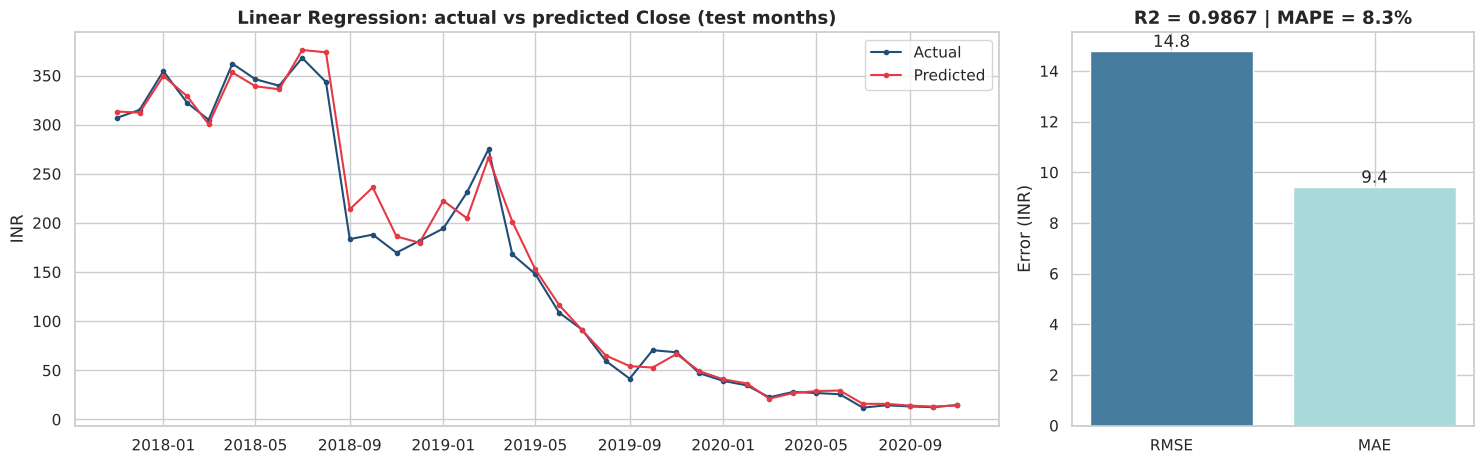

In [ ]:
# Visualizing evaluation Metric Score chart
plot_scores("Linear Regression", lr_pred, lr_scores)

**Linear Regression** models log(Close/Open) as a straight-line function of log(High/Open) and log(Low/Open); the fitted equation is log(Close/Open) = 0.001 + 0.786 x High_Rel + 0.668 x Low_Rel, and the prediction is converted back to rupees. On the 37 test months it scores **R-squared 0.9867, adjusted R-squared 0.9859, RMSE 14.79 INR, MAE 9.43 INR and MAPE 8.35%**. The 'Close = Open' benchmark scores R-squared 0.9085, RMSE 38.76 INR and MAPE 22.13%, so the model cuts both the RMSE and the MAPE by about 62%. Its predictions follow the actual price closely in calm months and drift away in the crash months (see the error analysis below).

#### 2. Cross- Validation & Hyperparameter Tuning

Plain Linear Regression CV RMSE (log-ratio) = 0.0586
Ridge: best parameters {'ridge__alpha': 0.001} | CV RMSE (log-ratio) = 0.0586


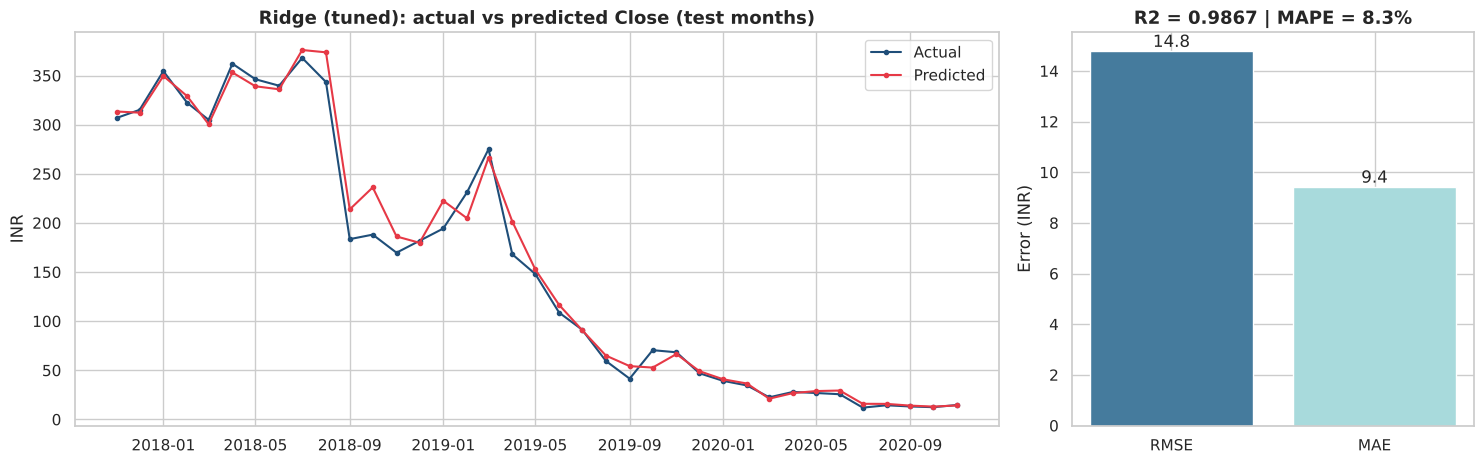

In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (GridSearchCV with time-series folds)
lr_cv = -cross_val_score(LinearRegression(), X_train, y_train, cv=TimeSeriesSplit(n_splits=5),
                         scoring="neg_root_mean_squared_error")
print(f"Plain Linear Regression CV RMSE (log-ratio) = {lr_cv.mean():.4f}")

# Fit the Algorithm: Ridge regression (regularised linear model); the scaler is inside the pipeline (no leakage)
ridge_search = tune("Ridge", Pipeline([("scale", StandardScaler()), ("ridge", Ridge())]),
                    {"ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100]})

# Predict on the model
ridge_pred, ridge_scores = score_model("Ridge (tuned)", ridge_search.best_estimator_)
plot_scores("Ridge (tuned)", ridge_pred, ridge_scores)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 5-fold expanding-window cross-validation** (`TimeSeriesSplit`) over the Ridge penalty alpha in {0.001, 0.01, 0.1, 1, 10, 100}. A grid search is cheap and exhaustive for one hyperparameter, and time-ordered folds respect the order of the data (ordinary k-fold would train on the future and validate on the past). The scaler is inside the pipeline so that it is refitted on each training fold.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No improvement, and that is informative.** The best alpha is the smallest value in the grid (0.001), the cross-validated RMSE is identical to plain Linear Regression (0.0586 on the log-ratio scale), and the test scores are identical (R-squared 0.9867, RMSE 14.79 INR, MAPE 8.35%). With only two almost uncorrelated features (VIF 1.0) and 148 rows there is nothing for regularisation to fix, so the simpler plain Linear Regression is kept.

### ML Model - 2

In [ ]:
# ML Model - 2 Implementation: Random Forest

# Fit the Algorithm
rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
rf.fit(X_train, y_train)

# Predict on the model
rf_pred, rf_scores = score_model("Random Forest", rf)
print({k: round(v, 4) for k, v in rf_scores.items()})

{'R2': 0.9803, 'Adj_R2': 0.9792, 'RMSE': np.float64(17.9749), 'MAE': 10.8693, 'MAPE_%': np.float64(10.7371)}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

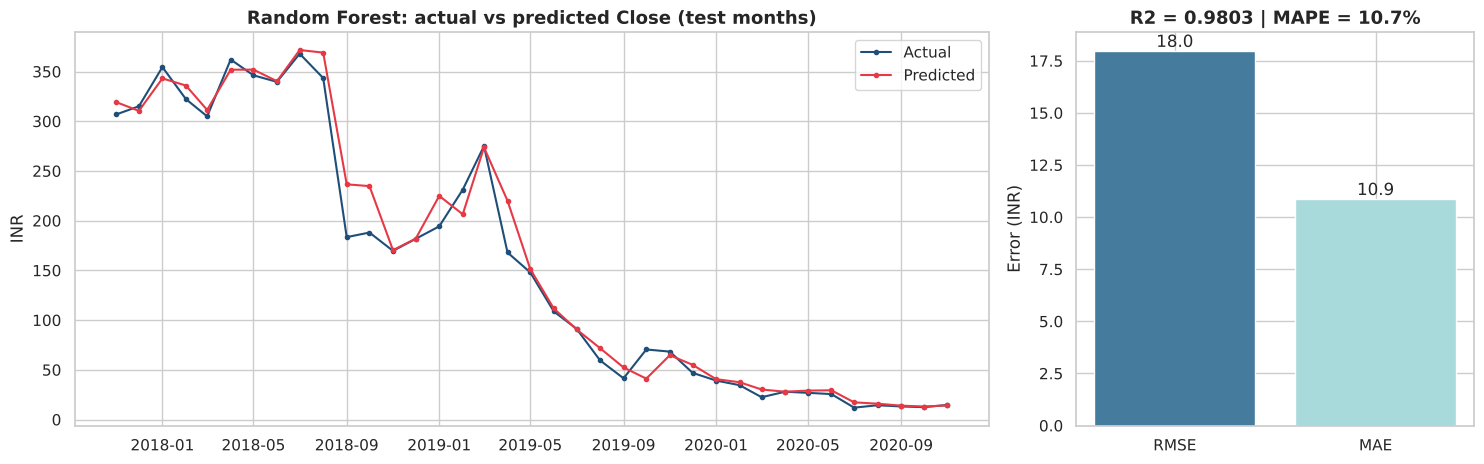

In [ ]:
# Visualizing evaluation Metric Score chart
plot_scores("Random Forest", rf_pred, rf_scores)

**Random Forest** averages 300 decision trees, each trained on a random sample of the months, which reduces overfitting. Test scores: **R-squared 0.9803, RMSE 17.97 INR, MAE 10.87 INR, MAPE 10.74%**: better than the benchmark but worse than Linear Regression. The relationship between the features and the target is essentially linear, so trees approximate a straight line with steps; in addition, trees cannot extrapolate beyond the feature values seen in training, and the test months are more extreme than the training months (scaled test standard deviations of 1.9 to 2.8).

#### 2. Cross- Validation & Hyperparameter Tuning

Random Forest: best parameters {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 400} | CV RMSE (log-ratio) = 0.0787


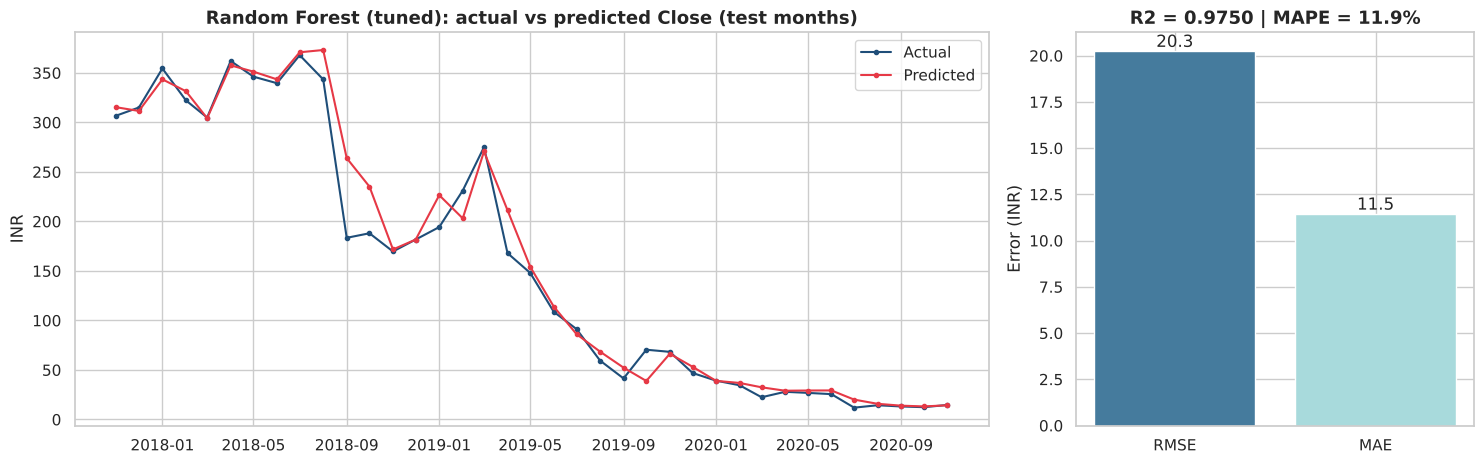

In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (GridSearchCV with time-series folds)

# Fit the Algorithm
rf_search = tune("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE),
                 {"n_estimators": [200, 400], "max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5, 10]})

# Predict on the model
rf_tuned_pred, rf_tuned_scores = score_model("Random Forest (tuned)", rf_search.best_estimator_)
plot_scores("Random Forest (tuned)", rf_tuned_pred, rf_tuned_scores)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 5 expanding time-series folds** over 32 combinations (number of trees 200/400, maximum depth 3/5/8/None, minimum samples per leaf 1/3/5/10), scored by RMSE. The grid is small enough to search exhaustively, which is more reliable than a random search here, and the time-ordered folds avoid leakage.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No, it got worse on the test months.** The best cross-validated setting (depth 5, minimum leaf size 5, 400 trees; CV RMSE 0.0787 on the log-ratio scale) lowered R-squared from 0.9803 to 0.9750, raised the RMSE from 17.97 to 20.26 INR and the MAPE from 10.74% to 11.86%. The cross-validation folds come from the calmer earlier history, so the settings that suit that history handle the crash months less well. Tuning on past data does not guarantee better results after a regime change, which is why the final test is held out and chronological.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **R-squared / adjusted R-squared:** the share of the variation in price explained. Business meaning: overall fit. Because prices trend strongly, even the 'Close = Open' benchmark scores 0.9085, so the improvement over that benchmark is what counts, not the headline value.
* **RMSE (INR):** typical error with big misses weighted more heavily. Business meaning: the size of a 'bad month' error that a risk or finance team should budget for. The final Linear Regression has 14.79 INR; the benchmark 38.76 INR.
* **MAE (INR):** average absolute error in rupees (9.43 INR for the final model): easy to explain to non-technical stakeholders.
* **MAPE (%):** average error relative to the price (8.35%). It is the fairest single metric here because a 10 INR miss is huge at a price of 15 and small at 350, and it can be compared across periods.

**Business impact:** an in-month estimate within about 8% on average (median 4.9%), and within 2.5% in calm months, is good enough for reporting, reconciliation and scenario analysis. It is not accurate enough, nor designed, for trading: the model needs the month's High and Low, which are not known in advance.

### ML Model - 3

In [ ]:
# ML Model - 3 Implementation: Gradient Boosting

# Fit the Algorithm
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb.fit(X_train, y_train)

# Predict on the model
gb_pred, gb_scores = score_model("Gradient Boosting", gb)
print({k: round(v, 4) for k, v in gb_scores.items()})

{'R2': 0.9808, 'Adj_R2': 0.9796, 'RMSE': np.float64(17.7723), 'MAE': 10.5731, 'MAPE_%': np.float64(10.747)}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

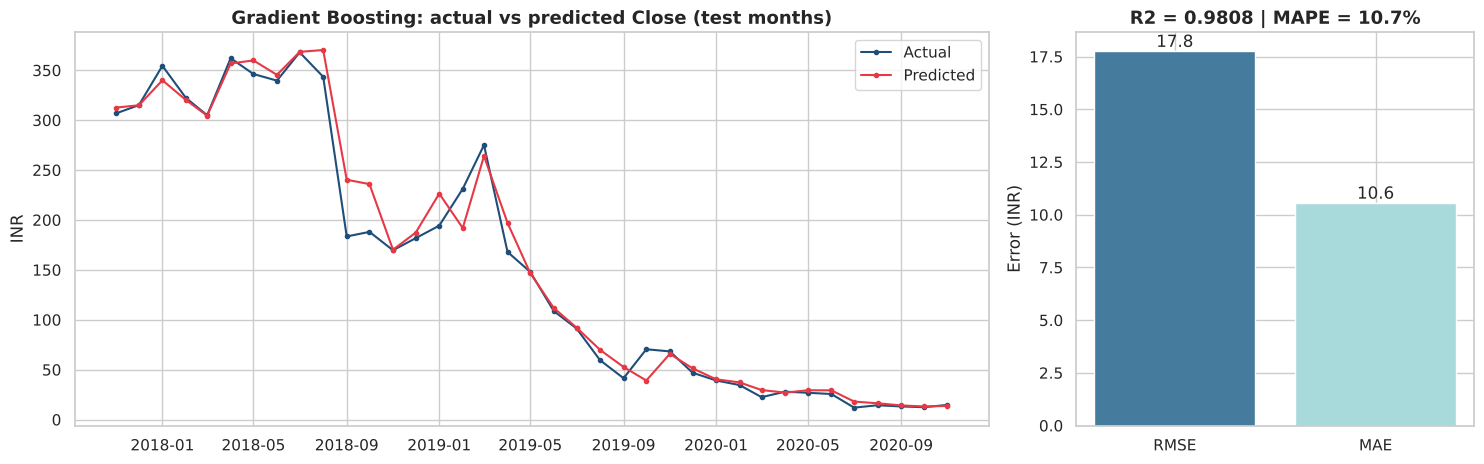

In [ ]:
# Visualizing evaluation Metric Score chart
plot_scores("Gradient Boosting", gb_pred, gb_scores)

**Gradient Boosting** builds shallow trees one after another, each correcting the errors of the previous ones. Default settings give **R-squared 0.9808, RMSE 17.77 INR, MAE 10.57 INR and MAPE 10.75%**, marginally better than the Random Forest and clearly better than the benchmark, but still behind Linear Regression, for the same reasons as for the Random Forest (a linear relationship and test features outside the training range).

#### 2. Cross- Validation & Hyperparameter Tuning

Gradient Boosting: best parameters {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 1.0} | CV RMSE (log-ratio) = 0.0799


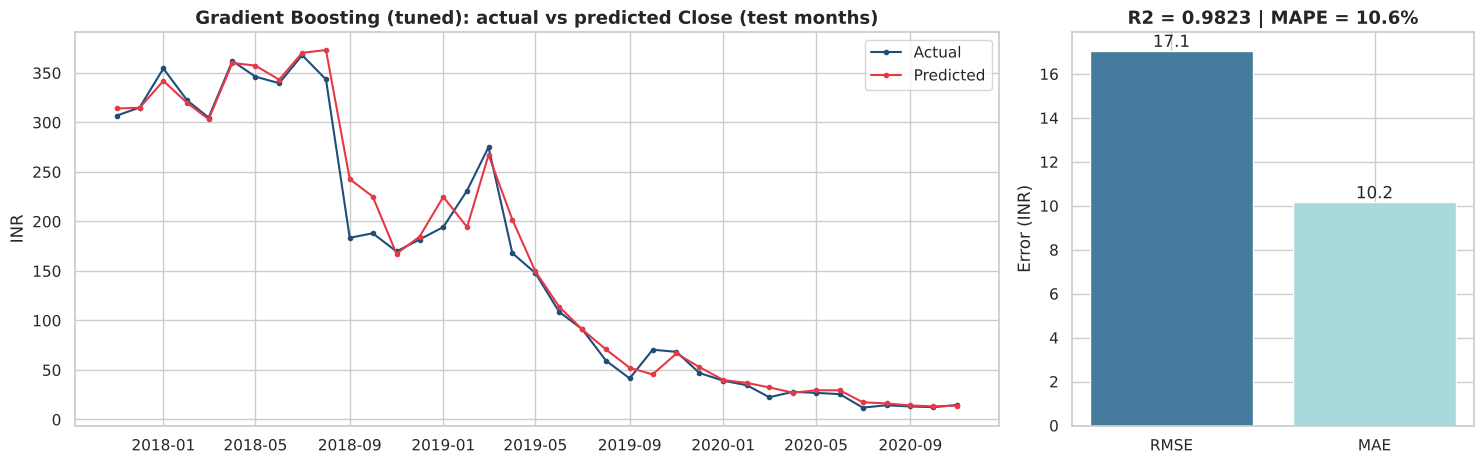

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (GridSearchCV with time-series folds)

# Fit the Algorithm
gb_search = tune("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE),
                 {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1], "max_depth": [2, 3], "subsample": [0.8, 1.0]})

# Predict on the model
gb_tuned_pred, gb_tuned_scores = score_model("Gradient Boosting (tuned)", gb_search.best_estimator_)
plot_scores("Gradient Boosting (tuned)", gb_tuned_pred, gb_tuned_scores)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 5 expanding time-series folds** over 16 combinations (100 or 300 trees, learning rate 0.03 or 0.1, depth 2 or 3, subsample 0.8 or 1.0), scored by RMSE. The grid is small, so an exhaustive search is affordable and reproducible.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**A small improvement.** The best setting (learning rate 0.03, depth 2, 300 trees, no subsampling; CV RMSE 0.0799) lifted R-squared from 0.9808 to 0.9823, lowered the RMSE from 17.77 to 17.05 INR, the MAE from 10.57 to 10.16 INR and the MAPE from 10.75% to 10.57%. A slower learning rate and shallower trees suit the small training set. The tuned model is still behind Linear Regression (RMSE 14.79 INR).

,R2,Adj_R2,RMSE,MAE,MAPE_%
Model,,,,,
Benchmark: Close = Open,0.9085,0.9085,38.7591,23.4597,22.1304
Linear Regression,0.9867,0.9859,14.7938,9.4338,8.3498
Ridge (tuned),0.9867,0.9859,14.7938,9.4338,8.3498
Random Forest,0.9803,0.9792,17.9749,10.8693,10.7371
Random Forest (tuned),0.9750,0.9735,20.2621,11.4605,11.8563
Gradient Boosting,0.9808,0.9796,17.7723,10.5731,10.7470
Gradient Boosting (tuned),0.9823,0.9812,17.0523,10.1612,10.5720


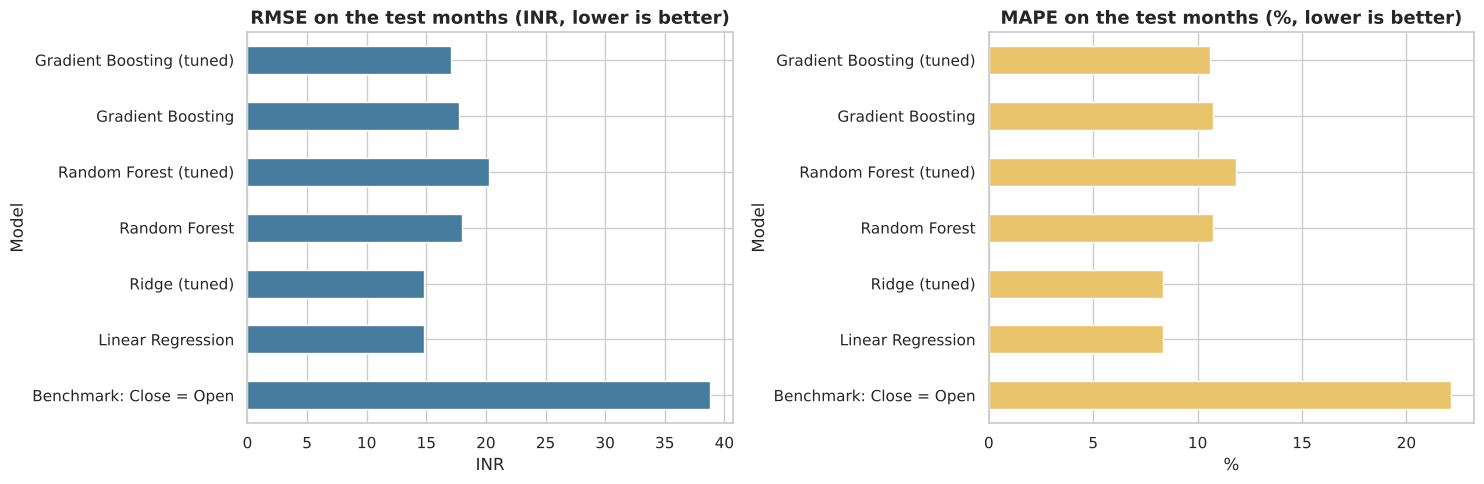

In [ ]:
# Compare all models on the same test months
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison["RMSE"].plot(kind="barh", ax=axes[0], color="#457b9d")
axes[0].set(title="RMSE on the test months (INR, lower is better)", xlabel="INR")
comparison["MAPE_%"].plot(kind="barh", ax=axes[1], color="#e9c46a")
axes[1].set(title="MAPE on the test months (%, lower is better)", xlabel="%")
plt.tight_layout()
plt.show()

In [ ]:
# Error analysis of the final model (Linear Regression): where does it miss?
err = test_df[["Date", "Open", "High", "Low", "Close"]].copy()
err["Predicted"] = lr_pred
err["Error_INR"] = err["Predicted"] - err["Close"]
err["Error_%"] = err["Error_INR"] / err["Close"] * 100
print("Five largest misses (INR):")
display(err.reindex(err["Error_INR"].abs().sort_values(ascending=False).index).head(5).round(1))

before = err["Date"] < "2018-09-01"
print(f"MAPE before Sep-2018 ({before.sum()} test months): {err.loc[before, 'Error_%'].abs().mean():.1f}%  |  "
      f"from Sep-2018 ({(~before).sum()} test months): {err.loc[~before, 'Error_%'].abs().mean():.1f}%")
print(f"Test months within +/-10% of the actual close: {(err['Error_%'].abs() <= 10).mean():.0%} | median absolute % error: {err['Error_%'].abs().median():.1f}%")
print(f"Share of the total squared error caused by the 5 worst months: {(err['Error_INR'] ** 2).nlargest(5).sum() / (err['Error_INR'] ** 2).sum():.0%}")
print(f"Months over-predicted: {(err['Error_INR'] > 0).mean():.0%} | mean error {err['Error_INR'].mean():+.1f} INR")

Five largest misses (INR):


,Date,Open,High,Low,Close,Predicted,Error_INR,Error_%
159,2018-10-01,180.0,268.4,168.6,188.0,236.1,48.1,25.6
165,2019-04-01,277.0,285.9,165.3,168.0,201.3,33.3,19.8
158,2018-09-01,347.2,350.0,166.2,183.4,213.7,30.3,16.5
157,2018-08-01,370.0,404.0,338.0,343.4,373.6,30.2,8.8
162,2019-01-01,182.8,236.3,181.2,194.3,222.5,28.2,14.5


MAPE before Sep-2018 (10 test months): 2.5%  |  from Sep-2018 (27 test months): 10.5%
Test months within +/-10% of the actual close: 76% | median absolute % error: 4.9%
Share of the total squared error caused by the 5 worst months: 75%
Months over-predicted: 59% | mean error +4.4 INR


**Where the model is weak.** The final model is accurate in calm months and loses accuracy in the crash: the MAPE is 2.5% in the 10 test months before Sep-2018 and 10.5% from Sep-2018 onwards, and the five worst months (Oct-18, Apr-19, Sep-18, Aug-18 and Jan-19) produce about three quarters of the total squared error. In most of these months the High is far above the Close, so the month's extremes say little about where it ends. 76% of the test months are within 10% of the actual close, and the median absolute error is 4.9%. The model over-predicts slightly more often than it under-predicts (59% of months, mean error +4.4 INR).

### Extra check: genuine next-month forecasting with rolling-origin validation

The main regression above estimates the current month's close using the current month's High and Low. Those values are not available before the month ends, so the saved Linear Regression model is not a next-month forecaster. This separate experiment uses only lagged returns and momentum features that would be available at each forecast origin.

The evaluation uses three expanding rolling-origin folds. Each fold fits on the past, calibrates a 90% split-conformal interval on the next 16 months, and then evaluates one-month-ahead forecasts on the following 10 months. The model is refit at each fold; the actual previous-month close and return are available when each subsequent one-month forecast is made. Feature ablation is limited to the first training window to avoid choosing features from the outer test results. The code below is self-contained and uses a relative CSV path.

,Feature set,Mean CV RMSE (INR),Fold RMSEs (INR)
0,Return lag 1,7.74,"5.87, 5.02, 7.61, 12.46"
1,Return lag 1 + 3-month momentum,7.82,"6.18, 5.06, 7.67, 12.38"
2,Return lag 1 + 3- and 6-month momentum,8.26,"7.85, 5.21, 7.66, 12.35"


Selected compact feature set: ['Return_Lag_1']


,Fold,Train months,Training through,Calibration,Test,Ridge RMSE (INR),Ridge MAPE (%),Persistence RMSE (INR),Persistence MAPE (%),90% coverage (%),Mean band width (INR),Mean band width (% close)
0,1,100,May-2014,Jun-2014 to Sep-2015,Oct-2015 to Jul-2016,14.30,6.00,16.65,7.48,90.0,67.54,38.43
1,2,126,Jul-2016,Aug-2016 to Nov-2017,Dec-2017 to Sep-2018,59.89,16.42,57.88,15.37,90.0,132.45,42.44
2,3,152,Sep-2018,Oct-2018 to Jan-2020,Feb-2020 to Nov-2020,6.50,28.25,6.33,25.76,90.0,28.67,144.97


,Method,RMSE (INR),MAE (INR),MAPE (%)
0,Ridge (selected compact feature set),35.75,19.26,16.89
1,Persistence (next close = prior close),34.97,19.05,16.21


Empirical 90% conformal coverage: 90% (27 of 30 holdout months)
Mean interval width: INR 76.22; 75.3% of actual close on average


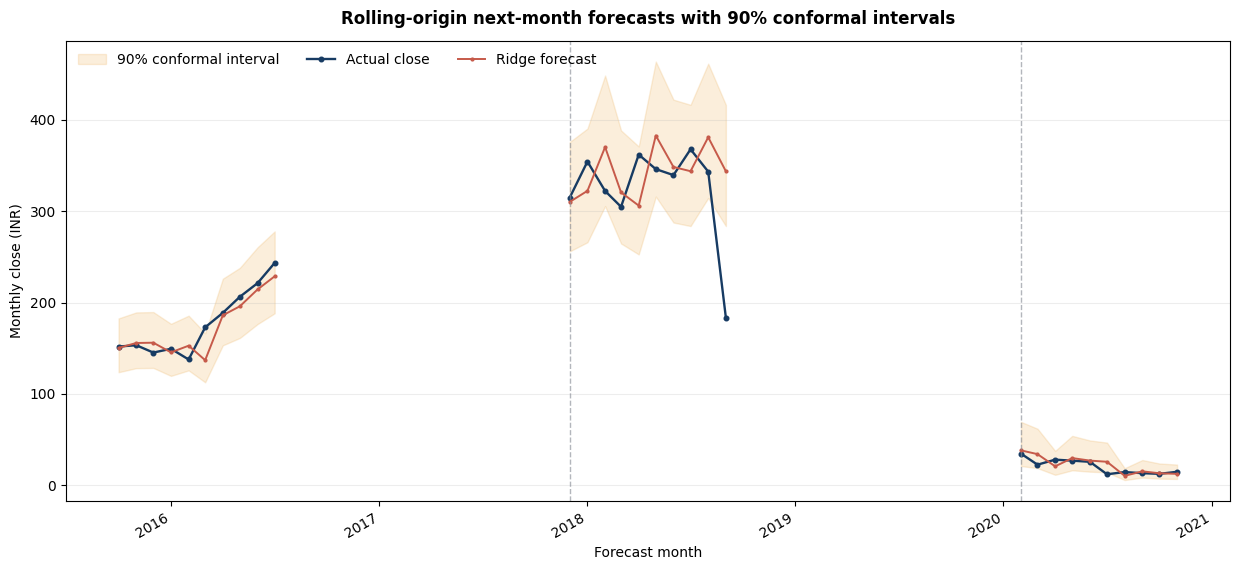

In [ ]:
# Reproducible rolling-origin forecast evaluation with split-conformal intervals
# This experiment forecasts one month ahead using only information available
# at the forecast origin. It is separate from the same-month High/Low estimator.
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load from the project root; no machine-specific absolute paths are used.
forecast_raw = pd.read_csv(Path("data_YesBank_StockPrices.csv"))
forecast_raw["Date"] = pd.to_datetime(forecast_raw["Date"], format="%b-%y")
forecast_raw = forecast_raw.sort_values("Date").reset_index(drop=True)

forecast = forecast_raw[["Date", "Close"]].copy()
forecast["Target_Log_Return"] = np.log(forecast["Close"]).diff()
forecast["Return_Lag_1"] = forecast["Target_Log_Return"].shift(1)
forecast["Return_Lag_2"] = forecast["Target_Log_Return"].shift(2)
forecast["Momentum_3M"] = np.log(forecast["Close"].shift(1) / forecast["Close"].shift(4))
forecast["Momentum_6M"] = np.log(forecast["Close"].shift(1) / forecast["Close"].shift(7))
forecast["Close_Lag_1"] = forecast["Close"].shift(1)
all_features = ["Return_Lag_1", "Return_Lag_2", "Momentum_3M", "Momentum_6M"]
forecast = forecast.dropna(subset=["Target_Log_Return", "Close_Lag_1"] + all_features).reset_index(drop=True)

# Ablation is confined to the first training window (before any outer holdout).
feature_sets = {
    "Return lag 1": ["Return_Lag_1"],
    "Return lag 1 + 3-month momentum": ["Return_Lag_1", "Momentum_3M"],
    "Return lag 1 + 3- and 6-month momentum": ["Return_Lag_1", "Momentum_3M", "Momentum_6M"],
}
initial_train_n, calibration_n, test_n = 100, 16, 10
initial_train = forecast.iloc[:initial_train_n]
ablation_rows = []
for name, cols in feature_sets.items():
    fold_rmses = []
    for tr_idx, val_idx in TimeSeriesSplit(n_splits=4).split(initial_train):
        tr, val = initial_train.iloc[tr_idx], initial_train.iloc[val_idx]
        candidate = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        candidate.fit(tr[cols], tr["Target_Log_Return"])
        val_return = candidate.predict(val[cols])
        val_close = val["Close_Lag_1"].to_numpy() * np.exp(val_return)
        fold_rmses.append(np.sqrt(mean_squared_error(val["Close"], val_close)))
    ablation_rows.append({"Feature set": name, "Mean CV RMSE (INR)": np.mean(fold_rmses),
                          "Fold RMSEs (INR)": ", ".join(f"{v:.2f}" for v in fold_rmses)})
ablation = pd.DataFrame(ablation_rows).sort_values("Mean CV RMSE (INR)").reset_index(drop=True)
display(ablation.round(2))
selected_features = feature_sets[ablation.iloc[0]["Feature set"]]
print("Selected compact feature set:", selected_features)

fold_rows, prediction_rows = [], []
alpha = 0.10  # nominal 90% two-sided interval
for fold_idx in range(3):
    train_end = initial_train_n + fold_idx * (calibration_n + test_n)
    train_fold = forecast.iloc[:train_end]
    calibration_fold = forecast.iloc[train_end:train_end + calibration_n]
    test_fold = forecast.iloc[train_end + calibration_n:train_end + calibration_n + test_n]

    # Fit only on the expanding training prefix.
    estimator = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    estimator.fit(train_fold[selected_features], train_fold["Target_Log_Return"])

    # Calibrate with the immediately following chronological block.
    calibration_pred = estimator.predict(calibration_fold[selected_features])
    abs_residuals = np.abs(calibration_fold["Target_Log_Return"].to_numpy() - calibration_pred)
    rank = min(int(np.ceil((len(abs_residuals) + 1) * (1 - alpha))), len(abs_residuals))
    q_hat = float(np.sort(abs_residuals)[rank - 1])

    # One-step-ahead rolling forecasts: each row uses the prior month's known close/return.
    pred_return = estimator.predict(test_fold[selected_features])
    prior_close = test_fold["Close_Lag_1"].to_numpy()
    pred_close = prior_close * np.exp(pred_return)
    lower = prior_close * np.exp(pred_return - q_hat)
    upper = prior_close * np.exp(pred_return + q_hat)
    actual = test_fold["Close"].to_numpy()
    persistence = prior_close
    covered = (actual >= lower) & (actual <= upper)

    fold_rows.append({
        "Fold": fold_idx + 1,
        "Train months": len(train_fold),
        "Training through": train_fold["Date"].iloc[-1].strftime("%b-%Y"),
        "Calibration": f"{calibration_fold['Date'].iloc[0]:%b-%Y} to {calibration_fold['Date'].iloc[-1]:%b-%Y}",
        "Test": f"{test_fold['Date'].iloc[0]:%b-%Y} to {test_fold['Date'].iloc[-1]:%b-%Y}",
        "Ridge RMSE (INR)": np.sqrt(mean_squared_error(actual, pred_close)),
        "Ridge MAPE (%)": np.mean(np.abs(pred_close / actual - 1)) * 100,
        "Persistence RMSE (INR)": np.sqrt(mean_squared_error(actual, persistence)),
        "Persistence MAPE (%)": np.mean(np.abs(persistence / actual - 1)) * 100,
        "90% coverage (%)": covered.mean() * 100,
        "Mean band width (INR)": np.mean(upper - lower),
        "Mean band width (% close)": np.mean((upper - lower) / actual) * 100,
    })
    for j, (_, row) in enumerate(test_fold.iterrows()):
        prediction_rows.append({"Date": row["Date"], "Actual close": actual[j],
                                "Ridge forecast": pred_close[j], "Persistence": persistence[j],
                                "Lower 90%": lower[j], "Upper 90%": upper[j],
                                "Covered": bool(covered[j]), "Fold": fold_idx + 1})

fold_results = pd.DataFrame(fold_rows)
predictions = pd.DataFrame(prediction_rows)
display(fold_results.round(2))

# Pooled results across the 30 distinct one-month-ahead holdout observations.
y = predictions["Actual close"].to_numpy()
pred_ridge = predictions["Ridge forecast"].to_numpy()
pred_persistence = predictions["Persistence"].to_numpy()
summary = pd.DataFrame([
    {"Method": "Ridge (selected compact feature set)",
     "RMSE (INR)": np.sqrt(mean_squared_error(y, pred_ridge)),
     "MAE (INR)": mean_absolute_error(y, pred_ridge),
     "MAPE (%)": np.mean(np.abs(pred_ridge / y - 1)) * 100},
    {"Method": "Persistence (next close = prior close)",
     "RMSE (INR)": np.sqrt(mean_squared_error(y, pred_persistence)),
     "MAE (INR)": mean_absolute_error(y, pred_persistence),
     "MAPE (%)": np.mean(np.abs(pred_persistence / y - 1)) * 100},
])
display(summary.round(2))
print(f"Empirical 90% conformal coverage: {predictions['Covered'].mean():.0%} "
      f"({predictions['Covered'].sum()} of {len(predictions)} holdout months)")
print(f"Mean interval width: INR {(predictions['Upper 90%'] - predictions['Lower 90%']).mean():.2f}; "
      f"{(((predictions['Upper 90%'] - predictions['Lower 90%']) / y).mean() * 100):.1f}% of actual close on average")

# Visualize actual closes, rolling forecasts and fold-specific conformal bands.
fig, ax = plt.subplots(figsize=(12.5, 5.8))
for fold_number, fold_predictions in predictions.groupby("Fold"):
    ax.fill_between(fold_predictions["Date"], fold_predictions["Lower 90%"], fold_predictions["Upper 90%"],
                    alpha=0.18, color="#E9A23B", label="90% conformal interval" if fold_number == 1 else None)
    ax.plot(fold_predictions["Date"], fold_predictions["Actual close"], marker="o", ms=3.3,
            linewidth=1.7, color="#173B63", label="Actual close" if fold_number == 1 else None)
    ax.plot(fold_predictions["Date"], fold_predictions["Ridge forecast"], marker=".", ms=4,
            linewidth=1.4, color="#C65A4A", label="Ridge forecast" if fold_number == 1 else None)
for fold in [2, 3]:
    boundary = predictions.loc[predictions["Fold"] == fold, "Date"].iloc[0]
    ax.axvline(boundary, color="#8A8F98", linestyle="--", linewidth=1, alpha=0.65)
ax.set_title("Rolling-origin next-month forecasts with 90% conformal intervals", pad=12, weight="bold")
ax.set_ylabel("Monthly close (INR)")
ax.set_xlabel("Forecast month")
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False, ncol=3, loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig(Path("figures") / "rolling_origin_conformal_intervals.png", dpi=180, bbox_inches="tight")
plt.show()


**Interpretation.** The feature ablation selects the single lagged-return feature because it has the lowest mean expanding-window CV RMSE on the first training prefix (INR 7.74). Adding 3-month momentum increases the mean CV RMSE to INR 7.82; adding both 3- and 6-month momentum increases it to INR 8.26. The outer evaluation contains 30 one-month-ahead holdout observations across three distinct periods. The selected Ridge model has pooled RMSE INR 35.75 and MAPE 16.89%, versus INR 34.97 and 16.21% for the persistence benchmark (next close = prior close). It therefore does **not** beat the simple benchmark overall.

The fold-specific 90% conformal intervals cover 27 of 30 holdout observations (90% empirical coverage). Their mean width is INR 76.22, or about 75.3% of the actual close on average. These broad bands express substantial uncertainty rather than providing a precise trading range. The calibration blocks contain only 16 months each, and monthly financial returns are dependent and subject to regime changes; standard conformal coverage guarantees rely on exchangeability and should not be assumed here.

**Conclusion:** the project supports an accurate in-month close estimate after the month's High and Low are known, but the historical data do not support a reliable next-month forecasting claim. The forecast experiment is retained as a transparent negative result, not as a deployable prediction model.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**MAPE and RMSE** (in INR), with MAE and R-squared as support.
* **MAPE** is the main metric because price levels range from 10 to 400, so errors must be judged relative to the price and should be comparable between calm and crash periods.
* **RMSE** is kept because large misses are what hurt a risk or finance team, and RMSE penalises them most.
* **MAE** gives the average rupee error in plain language.
* **R-squared** is reported but not relied on: prices trend, so even the 'Close = Open' benchmark scores 0.9085. The improvement over the benchmark (RMSE 38.76 to 14.79 INR, MAPE 22.1% to 8.35%) is the meaningful comparison.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Linear Regression** on the relative features High_Rel and Low_Rel. It has the best score on every metric (R-squared 0.9867, RMSE 14.79 INR, MAE 9.43 INR, MAPE 8.35%), ahead of tuned Gradient Boosting (RMSE 17.05, MAPE 10.57%), Gradient Boosting (17.77, 10.75%), Random Forest (17.97, 10.74%) and tuned Random Forest (20.26, 11.86%). Tuned Ridge is identical, so the simplest model is kept. It is also fully interpretable, fast, and it extrapolates beyond the training range, which matters because the test period is more extreme than the training period; tree models cannot do that.

**Limits:** it is an estimator that needs the month's High and Low, its error rises to about 10% in crash months, and it does not forecast (see the check above).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

,Linear Regression coefficient
High_Rel,0.7861
Low_Rel,0.6682
intercept,0.0010


,Permutation (final model),Random Forest (impurity),Gradient Boosting (impurity)
High_Rel,0.758,0.433,0.404
Low_Rel,1.623,0.567,0.596


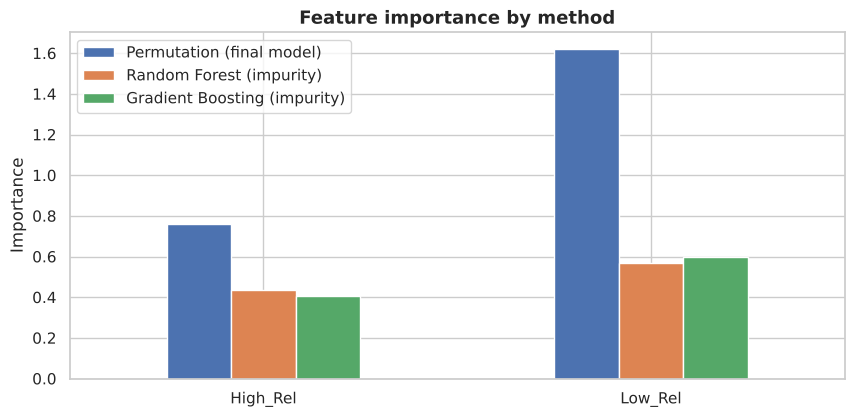

In [ ]:
# Model explainability: coefficients, permutation importance and tree importances
coef_table = pd.Series(lr.coef_, index=FEATURES).rename("Linear Regression coefficient").to_frame()
coef_table.loc["intercept"] = lr.intercept_
display(coef_table.round(4))

# Permutation importance on the test months: how much does the R2 drop when a feature is shuffled?
perm = permutation_importance(lr, X_test, y_test, n_repeats=50, random_state=RANDOM_STATE, scoring="r2")
imp = pd.DataFrame({"Permutation (final model)": perm.importances_mean,
                    "Random Forest (impurity)": rf.feature_importances_,
                    "Gradient Boosting (impurity)": gb.feature_importances_}, index=FEATURES)
display(imp.round(3))
imp.plot(kind="bar", figsize=(10, 4.5), rot=0, title="Feature importance by method")
plt.ylabel("Importance")
plt.show()

**Model used:** Linear Regression, log(Close/Open) = 0.001 + 0.786 x log(High/Open) + 0.668 x log(Low/Open). Reading the coefficients: a month whose high is 1% further above the open (in log terms) closes about 0.79% higher relative to its open, and a month whose low is 1% further below the open closes about 0.67% lower. In other words, the close is pulled towards both extremes of the month.

**Explainability tools:** (1) the coefficients above, (2) **permutation importance** on the test months (Low_Rel 1.62 vs High_Rel 0.76 drop in R-squared when shuffled), and (3) the impurity importances of the tree models (Low_Rel 0.57 and 0.60 vs High_Rel 0.43 and 0.40). All three agree that **the month's low is the more informative feature**. The intercept is essentially zero: with no extreme in either direction the close equals the open.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
# Save the File
Path("models").mkdir(exist_ok=True)
artifact = {"model": lr,                                   # final model: Linear Regression
            "features": FEATURES,
            "target": "log(Close/Open)",
            "trained_on": f"{df['Date'].iloc[0]:%b-%Y} to {df['Date'].iloc[split_idx - 1]:%b-%Y}"}
joblib.dump(artifact, "models/yes_bank_close_model.joblib")
print("Saved:", Path("models/yes_bank_close_model.joblib").resolve().name)

Saved: yes_bank_close_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [ ]:
# Load the File and predict unseen data.
loaded = joblib.load("models/yes_bank_close_model.joblib")

def predict_close(open_price, high, low, artifact=loaded):
    """Predict a month's closing price (INR) from its Open, High and Low, with input validation."""
    if not (0 < low <= open_price <= high):
        raise ValueError("Expected 0 < Low <= Open <= High (all in INR).")
    feats = pd.DataFrame({"High_Rel": [np.log(high / open_price)], "Low_Rel": [np.log(low / open_price)]})
    return float(to_price([open_price], artifact["model"].predict(feats[artifact["features"]]))[0])

# (a) Sanity check on unseen months (the last five months were never used for training)
check = df.iloc[-5:][["Date", "Open", "High", "Low", "Close"]].copy()
check["Predicted_Close"] = [predict_close(o, h, l) for o, h, l in zip(check["Open"], check["High"], check["Low"])]
check["Error_%"] = (check["Predicted_Close"] / check["Close"] - 1) * 100
display(check.round(2))
assert np.allclose(check["Predicted_Close"], to_price(check["Open"], lr.predict(model_df.iloc[-5:][FEATURES]))), "reloaded model differs"

# (b) A brand-new hypothetical month
print("Hypothetical month Open 14.0 / High 15.5 / Low 12.5 -> predicted Close:", round(predict_close(14.0, 15.5, 12.5), 2))
try:
    predict_close(14.0, 12.0, 15.0)                       # invalid input on purpose
except ValueError as err:
    print("Input validation works:", err)

,Date,Open,High,Low,Close,Predicted_Close,Error_%
180,2020-07-01,25.60,28.30,11.10,11.95,15.86,32.75
181,2020-08-01,12.00,17.16,11.85,14.37,15.78,9.80
182,2020-09-01,14.30,15.34,12.75,13.15,14.01,6.54
183,2020-10-01,13.30,14.01,12.11,12.42,13.03,4.88
184,2020-11-01,12.41,14.90,12.21,14.67,14.19,-3.29


Hypothetical month Open 14.0 / High 15.5 / Low 12.5 -> predicted Close: 14.07
Input validation works: Expected 0 < Low <= Open <= High (all in INR).


The model artifact was exported, reloaded, and sanity-checked locally. No live deployment or external service integration is included in this project.

# **Conclusion**

This project combines exploratory analysis, statistical testing, feature engineering, chronological model evaluation, explainability and a saved model artifact. **In-month estimation:** Linear Regression on log(High/Open) and log(Low/Open) achieved R-squared 0.9867, RMSE INR 14.79, MAE INR 9.43 and MAPE 8.35% on 37 held-out months. This is an estimate of the current month's close after its High and Low are known, not a forecast made before the month starts.

**Next-month forecasting:** a separate compact Ridge model using the prior month's return was evaluated on three rolling-origin holdouts (30 one-month-ahead observations) with 16-month calibration blocks and 10-month test blocks. Its pooled RMSE was INR 35.75 and MAPE 16.89%, slightly worse than persistence (INR 34.97 RMSE and 16.21% MAPE). The 90% conformal bands covered 90% of the 30 holdout observations but were wide (mean INR 76.22). The data therefore do not justify a reliable next-month forecast.

**Recommendation:** retain the saved two-feature Linear Regression only as an in-month analytical estimator, label its information timing clearly, and do not use either model as standalone investment or trading advice. Future work should add a longer and more current history, market-wide covariates, and more calibration periods before claiming forecast skill.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***